# SUPERVISED LEARNING

# REGRESSION

## 1:LINEAR REGRESSION

### 1A: Simple Linear Regression

### Import pandas

In [1]:
import pandas as pd

## Read the dataset with pandas

In [2]:
df = pd.read_csv('Downloads/tvmarketing.csv')

### View the first five rows of the dataset

In [3]:
df.head()

,TV,Sales
0,230.1,22.1
1,44.5,10.4
2,17.2,9.3
3,151.5,18.5
4,180.8,12.9


### View the last 5 rows

In [4]:
df.tail()

,TV,Sales
195,38.2,7.6
196,94.2,9.7
197,177.0,12.8
198,283.6,25.5
199,232.1,13.4


### Check info about the dataset

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   TV      200 non-null    float64
 1   Sales   200 non-null    float64
dtypes: float64(2)
memory usage: 3.3 KB


### Check the number of rows and columns in the dataset

In [6]:
df.shape

(200, 2)

### Quick view the basic statistical information about the dataset

In [7]:
df.describe()

,TV,Sales
count,200.000000,200.000000
mean,147.042500,14.022500
std,85.854236,5.217457
min,0.700000,1.600000
25%,74.375000,10.375000
50%,149.750000,12.900000
75%,218.825000,17.400000
max,296.400000,27.000000


## Visualising the data using Seaborn Library

### Import Matplotlib, Seaborn and set matplotlib inline

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

### Visualize the relationship between the features and the response using scatterplots

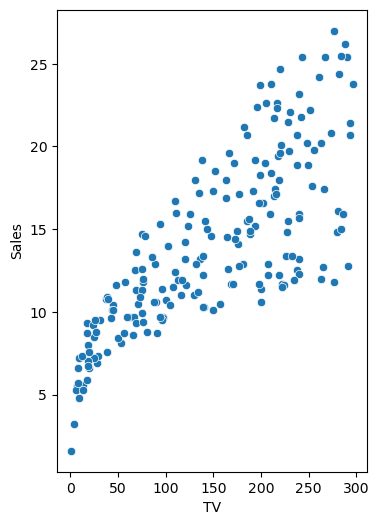

In [9]:
plt.figure(figsize = (4,6))
sns.scatterplot(x = "TV", y = "Sales", data = df)
plt.show()

### Performing Simple Linear Regression

### Assign feature variable(Independent variable) to X

In [10]:
X = df[['TV']]

### Print the first five rows of X

In [11]:
X.head()

,TV
0,230.1
1,44.5
2,17.2
3,151.5
4,180.8


### Assign response variable(Dependent variable or target variable) to y

In [12]:
y = df['Sales']

### Split the data into Training and testing Sets

In [13]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y , test_size = 0.3, random_state = 100)

### Check the shape of training and testing set

In [15]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(140, 1)
(140,)
(60, 1)
(60,)


### Performing Linear Regression

### Import LinearRegression from sklearn linear model

In [16]:
from sklearn.linear_model import LinearRegression

### Create a LinearRegression object

In [17]:
lr = LinearRegression()

### Train the model (lr) using fit

In [18]:
lr.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


### Print the coefficient and Intercept 

In [19]:
print(lr.coef_)
print(lr.intercept_)

[0.04649736]
6.989665857411681


### Check the score of our model

In [20]:
lr.score(X_train, y_train)

0.6134312469429993

### Make predictions on the testing set

In [21]:
y_pred = lr.predict(X_test)

### Plot a graph to check the accuracy of our prediction

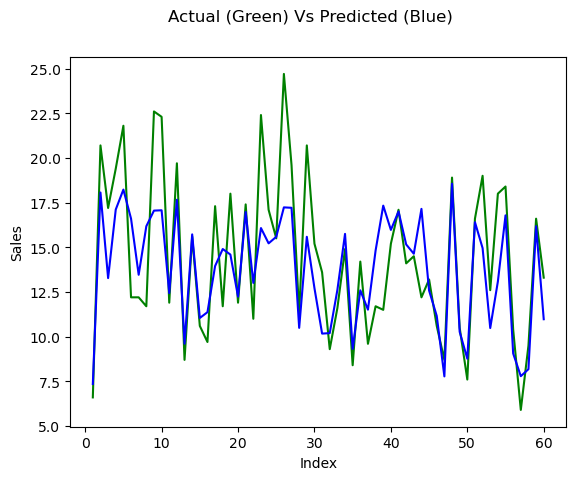

In [22]:
c = [i for i in range(1,61,1)]   #Creating an Index, 61 is used because we have a total of 60 data in our testing set
fig = plt.figure()
plt.plot(c,y_test, color = 'green') # Plotting y test
plt.plot(c,y_pred, color = 'blue') # Plotting predicted values
fig.suptitle('Actual (Green) Vs Predicted (Blue)') # Set title
plt.xlabel('Index') # Set X label
plt.ylabel('Sales') # Set Y label
plt.show()

### Plot a scatterplot of actual values vs predicted

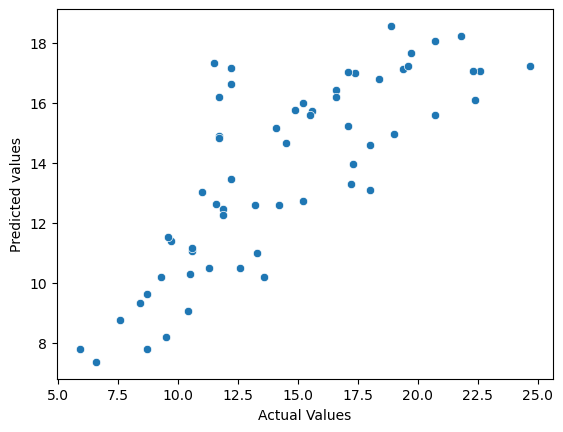

In [23]:
sns.scatterplot(x = y_test, y = y_pred)
plt.xlabel('Actual Values')
plt.ylabel('Predicted values')
plt.show()

### Calculate mean squared error and r2_score

### Import mean_squared_error and r2_score from sklearn.metrics

In [24]:
from sklearn.metrics import mean_squared_error,r2_score

### Calculate the mean squared error

In [25]:
mean_squared_error(y_test, y_pred)

7.975798532854849

### Calculate r2_score

In [26]:
r2_score(y_test, y_pred)

0.5942987267783302

### 1:B Multiple Linear Regression

### Import necessary libraries

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Read car_data.csv and store it in a variable

In [28]:
df = pd.read_csv('Downloads/car_data.csv')

### View the first five rows

In [29]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


### View the last five rows

In [30]:
df.tail()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
296,city,2016,9.50,11.6,33988,Diesel,Dealer,Manual,0
297,brio,2015,4.00,5.9,60000,Petrol,Dealer,Manual,0
298,city,2009,3.35,11.0,87934,Petrol,Dealer,Manual,0
299,city,2017,11.50,12.5,9000,Diesel,Dealer,Manual,0
300,brio,2016,5.30,5.9,5464,Petrol,Dealer,Manual,0


### Check the database info

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


### Gather the basic statistical information about the dataset

In [32]:
df.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


### Check the shape of the dataframe

In [33]:
df.shape

(301, 9)

### Check if there are any null values

In [34]:
df.isnull().sum()

Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

### Change the Year to number of years

In [35]:
current_year = 2021
df['Year'] = current_year - df['Year']

In [36]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,7,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,8,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,4,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,10,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,7,4.60,6.87,42450,Diesel,Dealer,Manual,0


### Drop Car_Name column

In [37]:
df.drop(columns = ['Car_Name'], inplace = True)

In [38]:
df.head()

,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,7,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,8,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,4,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,10,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,7,4.60,6.87,42450,Diesel,Dealer,Manual,0


### Change the categorical variables into numerical by OneHotEncoding (Use pd.get_dummies)

In [39]:
newdf = pd.get_dummies(df, drop_first = True)
newdf.head()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Individual,Transmission_Manual
0,7,3.35,5.59,27000,0,False,True,False,True
1,8,4.75,9.54,43000,0,True,False,False,True
2,4,7.25,9.85,6900,0,False,True,False,True
3,10,2.85,4.15,5200,0,False,True,False,True
4,7,4.60,6.87,42450,0,True,False,False,True


## Visualization

### Plot a pair plot

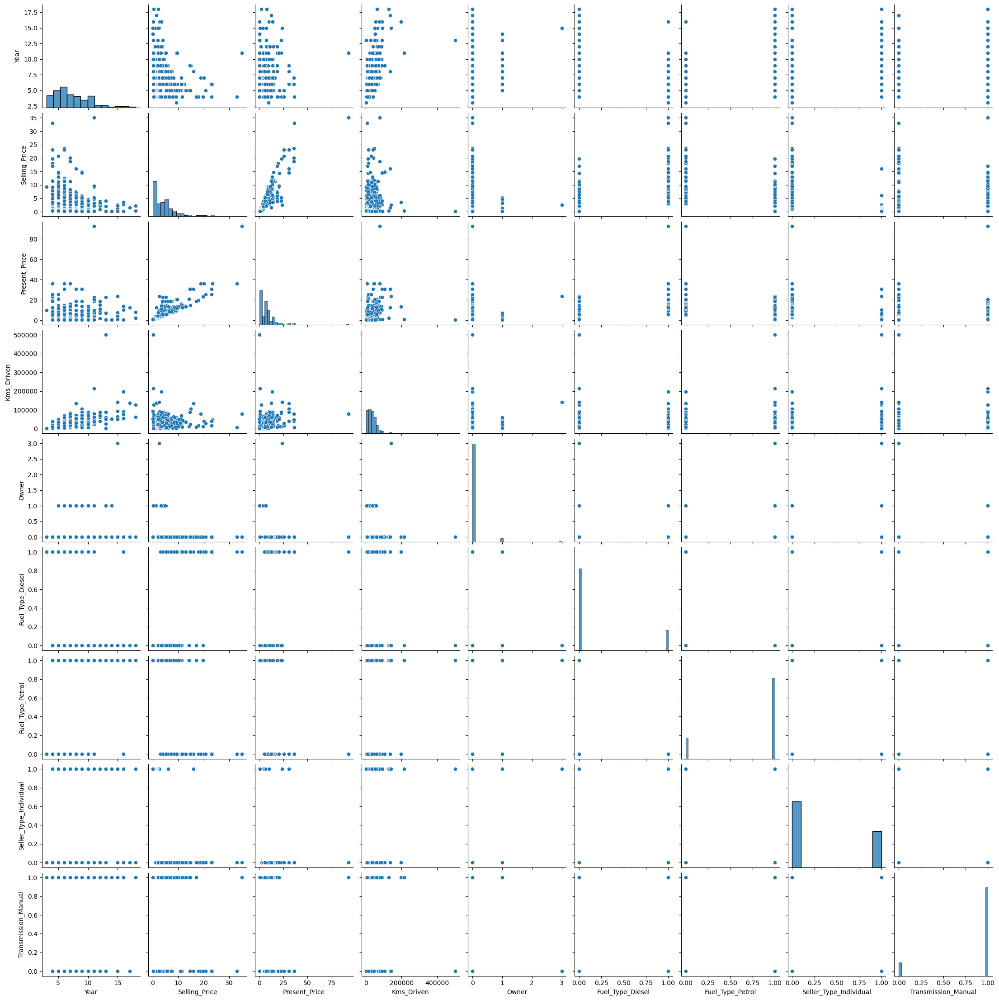

In [40]:
sns.pairplot(newdf)
plt.show()

### Plot a heatmap

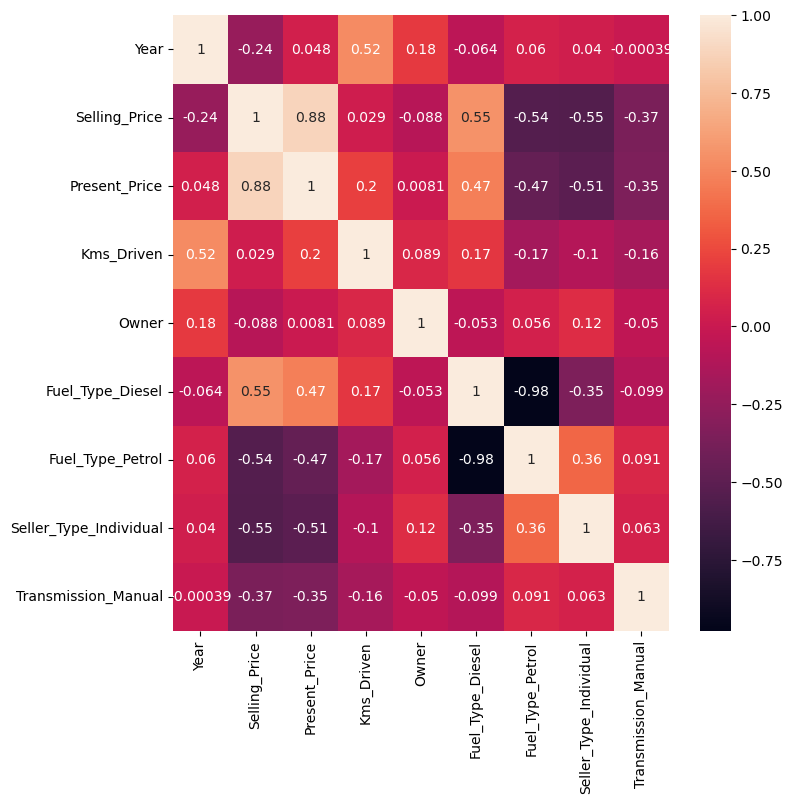

In [41]:
plt.figure(figsize = (8,8))
sns.heatmap(newdf.corr(), annot = True)
plt.show()

### Assign X and y variables(independent and dependent variables)

In [57]:
X = newdf[['Year', 'Present_Price', 'Kms_Driven', 'Owner',
       'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Seller_Type_Individual',
       'Transmission_Manual']]
y = newdf['Selling_Price']

### Standardise the data using Standard Scaler

In [58]:
from sklearn.preprocessing import StandardScaler

In [59]:
scaler = StandardScaler()

In [60]:
xcolumns = X.columns

In [61]:
X = scaler.fit_transform(X)

In [64]:
X = pd.DataFrame(X, columns = xcolumns)
X.head()

,Year,Present_Price,Kms_Driven,Owner,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Individual,Transmission_Manual
0,-0.128897,-0.236215,-0.256224,-0.174501,-0.498962,0.509327,-0.737285,0.39148
1,0.217514,0.221505,0.155911,-0.174501,2.004162,-1.963374,-0.737285,0.39148
2,-1.168129,0.257427,-0.773969,-0.174501,-0.498962,0.509327,-0.737285,0.39148
3,0.910335,-0.403079,-0.817758,-0.174501,-0.498962,0.509327,-0.737285,0.39148
4,-0.128897,-0.087890,0.141743,-0.174501,2.004162,-1.963374,-0.737285,0.39148


### Check the shape of X and y

In [65]:
X.shape

(301, 8)

In [66]:
y.shape

(301,)

### Split the data into training and testing set

In [67]:
from sklearn.model_selection import train_test_split

In [68]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state=100)

### Check the size of X_train and X_test

In [69]:
X_train.size

1680

In [70]:
X_test.size

728

### Create a Linear Regression Model and Train it

In [71]:
from sklearn.linear_model import LinearRegression

In [72]:
model = LinearRegression()

In [73]:
#Train the model
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


### Check the score of our model

In [74]:
model.score(X_train, y_train)

0.895560836468798

### Print the values of coefficents

In [75]:
pd.DataFrame(model.coef_, index = X_test.columns, columns = ['Coefficeints'])

,Coefficeints
Year,-1.108809
Present_Price,3.484620
Kms_Driven,-0.185312
Owner,0.146933
Fuel_Type_Diesel,0.984041
Fuel_Type_Petrol,0.167000
Seller_Type_Individual,-0.536205
Transmission_Manual,-0.537119


### Predict for X_test and store it in a variable

In [76]:
y_pred = model.predict(X_test)

### Evaluate the prediction with mean squared error and r2 score

In [77]:
from sklearn import metrics

In [78]:
print ('Mean Squared Error is: ', metrics.mean_squared_error(y_test, y_pred))

Mean Squared Error is:  4.390781949926883


In [79]:
print('r2 Score is: ', metrics.r2_score(y_test, y_pred) )

r2 Score is:  0.8316982715837706


### Plot a scatterplot of actual vs predicted values

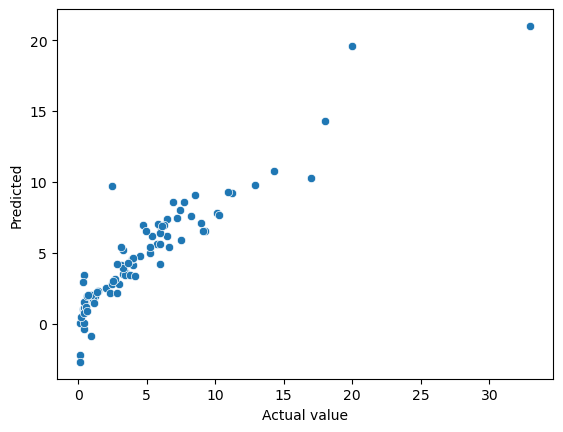

In [80]:
sns.scatterplot(x = y_test, y = y_pred)
plt.xlabel('Actual value')
plt.ylabel('Predicted')
plt.show()

### Plot a graph to check the accuracy of our prediction

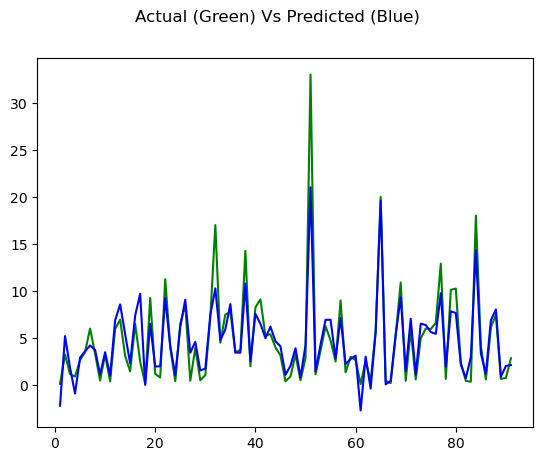

In [82]:
c = [i for i in range(1,92,1)]   #Creating an Index, 61 is used because we have a total of 60 data in our testing set
fig = plt.figure()
plt.plot(c,y_test, color = 'green') # Plotting y test
plt.plot(c,y_pred, color = 'blue') # Plotting predicted values
fig.suptitle('Actual (Green) Vs Predicted (Blue)') # Set title
plt.show()

## 2:POLYNOMIAL REGRESSION

# CLASSIFICATION

## 1:LOGISTIC REGRESSION

### Titanic - Machine Learning from Disaster 

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('Downloads/titanic.csv')

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [7]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [9]:
# Check the unique values in Embarked

df['Embarked'].unique()

array(['S', 'C', 'Q', nan], dtype=object)

In [10]:
# Remove unwanted features (PassengerId,Name, ticket, Cabin)

df.drop(columns = ['PassengerId', 'Name', 'Ticket', 'Cabin'], inplace = True)

In [11]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [12]:
df['Age'].fillna(df['Age'].mean(), inplace = True)

C:\Users\varsh\AppData\Local\Temp\ipykernel_3416\2940318962.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean(), inplace = True)


In [13]:
df.isna().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    2
dtype: int64

In [14]:
df['Embarked'].fillna('Unknown', inplace = True)

C:\Users\varsh\AppData\Local\Temp\ipykernel_3416\1600491372.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Embarked'].fillna('Unknown', inplace = True)


In [15]:
df.isna().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

In [16]:
# Convert the categorical datas into numerical ('Sex', 'Embarked')

df = pd.get_dummies(df, drop_first= True)

In [17]:
df.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S,Embarked_Unknown
0,0,3,22.0,1,0,7.2500,True,False,True,False
1,1,1,38.0,1,0,71.2833,False,False,False,False
2,1,3,26.0,0,0,7.9250,False,False,True,False
3,1,1,35.0,1,0,53.1000,False,False,True,False
4,0,3,35.0,0,0,8.0500,True,False,True,False


In [18]:
X = df.drop(columns = ['Survived'])
X

,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S,Embarked_Unknown
0,3,22.000000,1,0,7.2500,True,False,True,False
1,1,38.000000,1,0,71.2833,False,False,False,False
2,3,26.000000,0,0,7.9250,False,False,True,False
3,1,35.000000,1,0,53.1000,False,False,True,False
4,3,35.000000,0,0,8.0500,True,False,True,False
...,...,...,...,...,...,...,...,...,...
886,2,27.000000,0,0,13.0000,True,False,True,False
887,1,19.000000,0,0,30.0000,False,False,True,False
888,3,29.699118,1,2,23.4500,False,False,True,False
889,1,26.000000,0,0,30.0000,True,False,False,False


In [19]:
y = df['Survived']
y

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64

In [20]:
X.shape

(891, 9)

In [21]:
y.shape

(891,)

In [22]:
from sklearn.preprocessing import StandardScaler

In [23]:
scaler = StandardScaler()

In [24]:
xcolumns = X.columns

In [25]:
X = scaler.fit_transform(X)

In [26]:
X = pd.DataFrame(X, columns = xcolumns)

In [27]:
X.head()

,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S,Embarked_Unknown
0,0.827377,-0.592481,0.432793,-0.473674,-0.502445,0.737695,-0.307562,0.619306,-0.047431
1,-1.566107,0.638789,0.432793,-0.473674,0.786845,-1.355574,-0.307562,-1.614710,-0.047431
2,0.827377,-0.284663,-0.474545,-0.473674,-0.488854,-1.355574,-0.307562,0.619306,-0.047431
3,-1.566107,0.407926,0.432793,-0.473674,0.420730,-1.355574,-0.307562,0.619306,-0.047431
4,0.827377,0.407926,-0.474545,-0.473674,-0.486337,0.737695,-0.307562,0.619306,-0.047431


[]

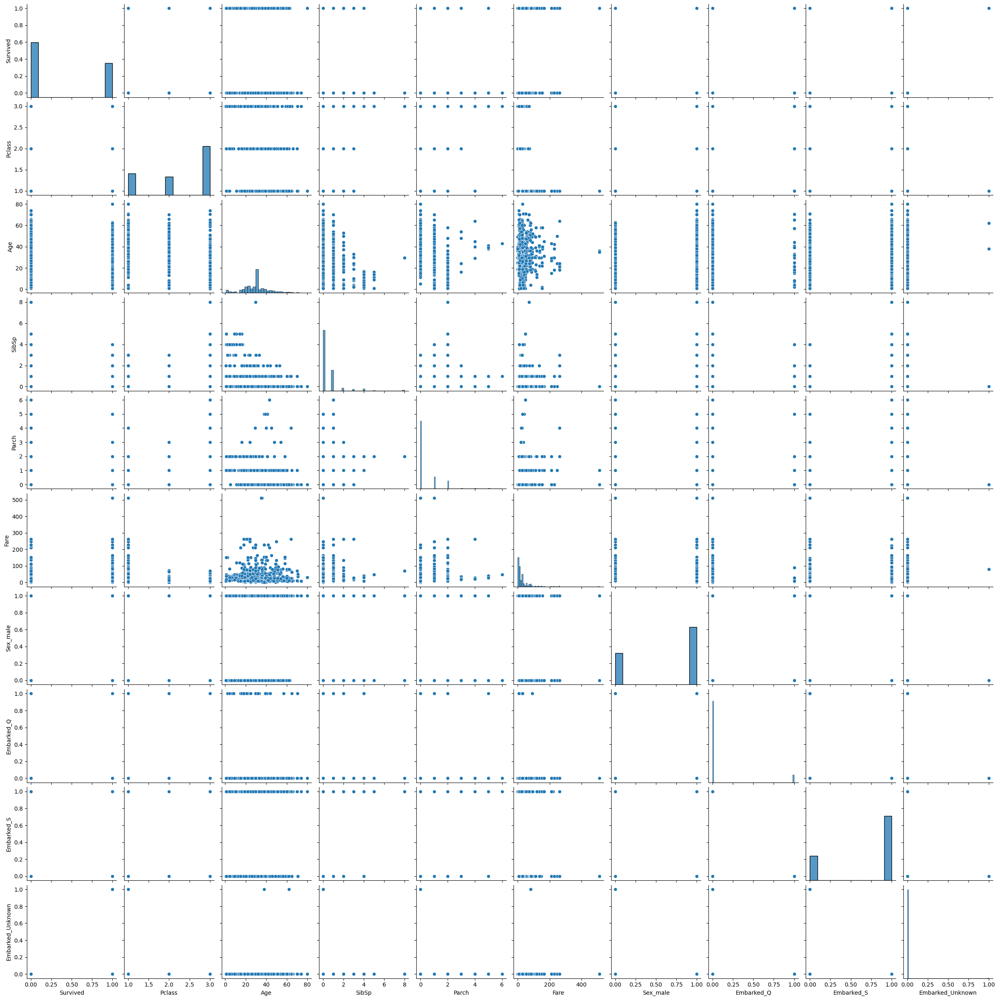

In [28]:
sns.pairplot(df)
plt.plot()

[]

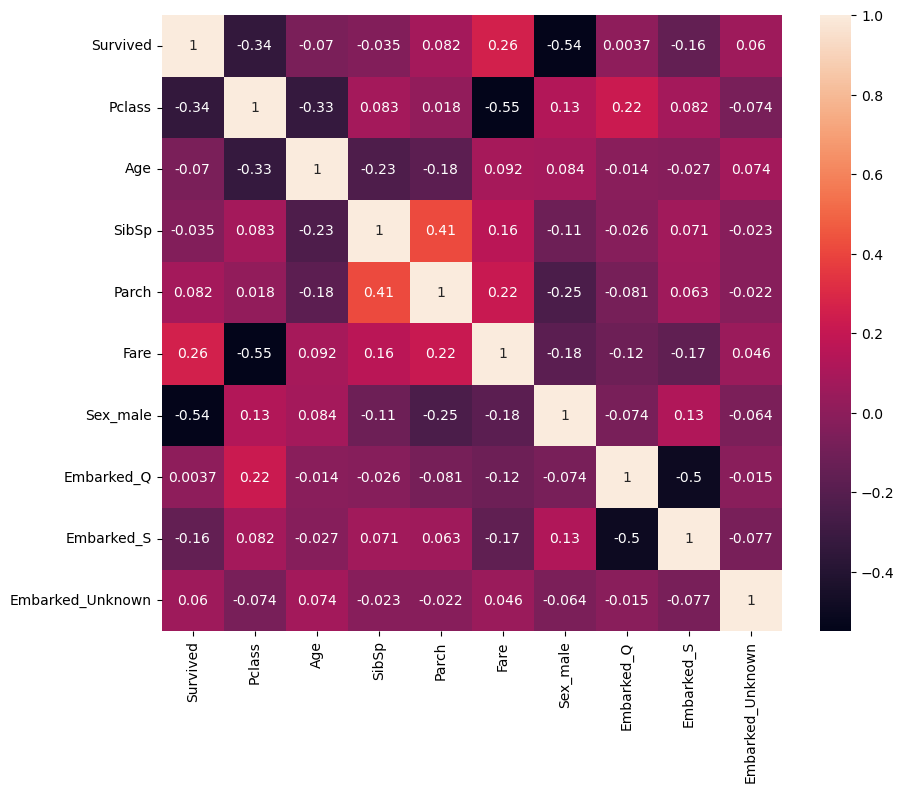

In [29]:
plt.figure(figsize = (10,8))
sns.heatmap(df.corr(), annot = True)
plt.plot()

In [30]:
from sklearn.model_selection import train_test_split

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state= 100)

In [32]:
X_train.shape

(623, 9)

In [33]:
X_test.shape

(268, 9)

In [34]:
from sklearn.linear_model import LogisticRegression

In [35]:
model = LogisticRegression()

In [36]:
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [37]:
model.score(X_train,y_train)

0.8089887640449438

In [38]:
y_pred = model.predict(X_test)
y_pred

array([1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1,
       0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0,
       0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1,
       0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1,
       0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0,
       1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0,
       0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1,
       1, 0, 1, 0])

In [54]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [55]:
accuracy_score(y_test, y_pred)

0.7910447761194029

In [56]:
confusion_matrix(y_test,y_pred)

array([[139,  20],
       [ 36,  73]])

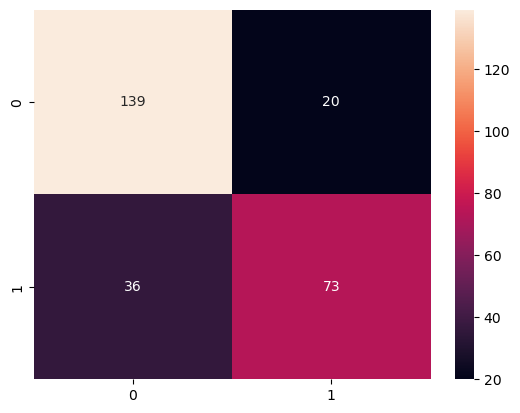

In [57]:
# Plot confusion matrix

sns.heatmap(confusion_matrix(y_test,y_pred), annot = True, fmt = 'd')
plt.show()

In [58]:
classification_report(y_test,y_pred)

'              precision    recall  f1-score   support\n\n           0       0.79      0.87      0.83       159\n           1       0.78      0.67      0.72       109\n\n    accuracy                           0.79       268\n   macro avg       0.79      0.77      0.78       268\nweighted avg       0.79      0.79      0.79       268\n'

## 2: KNN 

### Heart Failure Prediction

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Downloads/heart.csv')

In [3]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [5]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [6]:
df.isna().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [7]:
categorical_features = ['Sex','ChestPainType', 'RestingECG','ExerciseAngina','ST_Slope']
for i in categorical_features:
    print('Unique elements in ', i,'are: ', df[i].unique())

Unique elements in  Sex are:  ['M' 'F']
Unique elements in  ChestPainType are:  ['ATA' 'NAP' 'ASY' 'TA']
Unique elements in  RestingECG are:  ['Normal' 'ST' 'LVH']
Unique elements in  ExerciseAngina are:  ['N' 'Y']
Unique elements in  ST_Slope are:  ['Up' 'Flat' 'Down']


In [8]:
newdf = pd.get_dummies(df, drop_first = True)
newdf.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0.0,0,True,True,False,False,True,False,False,False,True
1,49,160,180,0,156,1.0,1,False,False,True,False,True,False,False,True,False
2,37,130,283,0,98,0.0,0,True,True,False,False,False,True,False,False,True
3,48,138,214,0,108,1.5,1,False,False,False,False,True,False,True,True,False
4,54,150,195,0,122,0.0,0,True,False,True,False,True,False,False,False,True


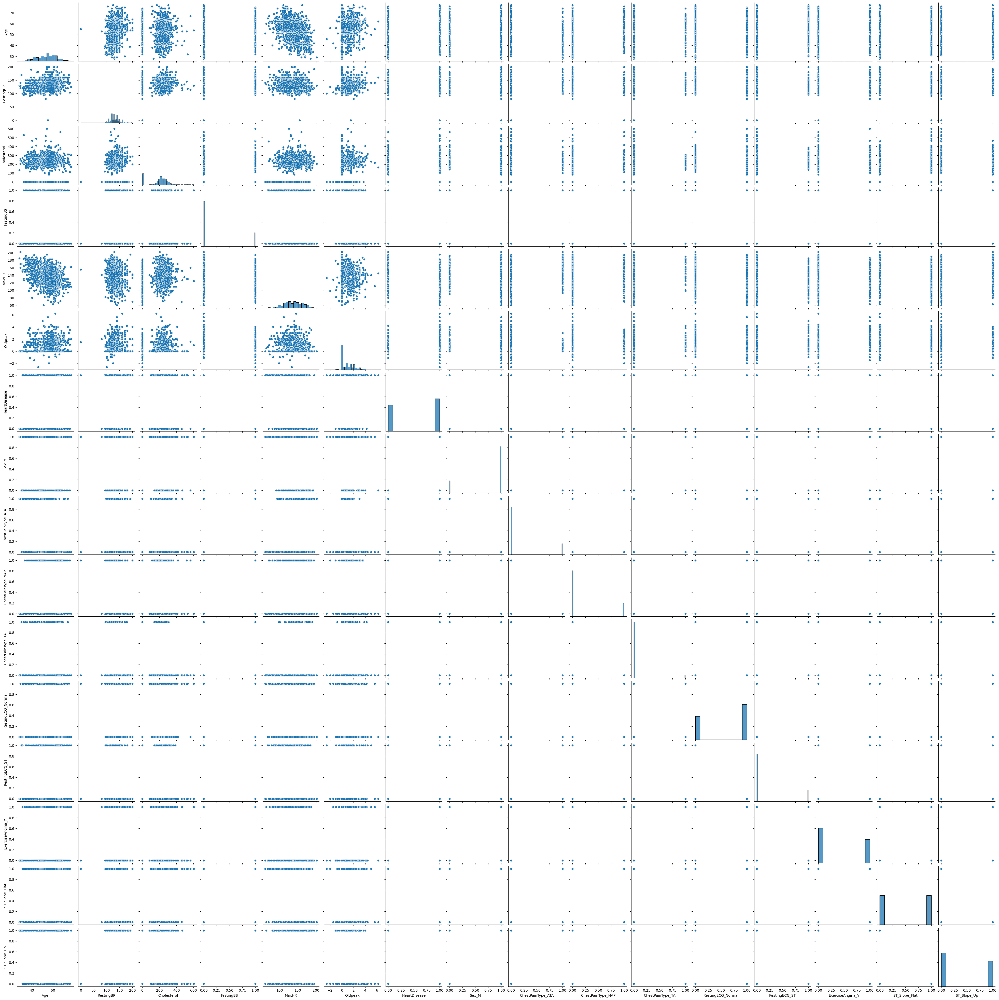

In [9]:
sns.pairplot(newdf)
plt.show()

In [10]:
X = newdf.drop(columns = ['HeartDisease'])
y = newdf['HeartDisease']

In [11]:
from sklearn.preprocessing import StandardScaler

In [12]:
scaler = StandardScaler()

In [13]:
xcolumns = X.columns

In [14]:
X = scaler.fit_transform(X)

In [15]:
X = pd.DataFrame(X, columns = xcolumns)

In [16]:
X.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,-1.433140,0.410909,0.825070,-0.551341,1.382928,-0.832432,0.515952,2.075177,-0.532838,-0.229679,0.814275,-0.490449,-0.823556,-1.002181,1.150674
1,-0.478484,1.491752,-0.171961,-0.551341,0.754157,0.105664,-1.938163,-0.481887,1.876744,-0.229679,0.814275,-0.490449,-0.823556,0.997824,-0.869056
2,-1.751359,-0.129513,0.770188,-0.551341,-1.525138,-0.832432,0.515952,2.075177,-0.532838,-0.229679,-1.228087,2.038947,-0.823556,-1.002181,1.150674
3,-0.584556,0.302825,0.139040,-0.551341,-1.132156,0.574711,-1.938163,-0.481887,-0.532838,-0.229679,0.814275,-0.490449,1.214246,0.997824,-0.869056
4,0.051881,0.951331,-0.034755,-0.551341,-0.581981,-0.832432,0.515952,-0.481887,1.876744,-0.229679,0.814275,-0.490449,-0.823556,-1.002181,1.150674


In [17]:
from sklearn.model_selection import train_test_split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y , test_size = 0.3, random_state = 100)

In [19]:
X_train.shape

(642, 15)

In [20]:
X_test.shape

(276, 15)

In [21]:
# Create a KNN model and train it
# Remember that we are trying to come up with a model to predict whether someone will have Heart Disease or Not. We'll start with k=1.

from sklearn.neighbors import KNeighborsClassifier

In [22]:
model = KNeighborsClassifier(n_neighbors=1)

In [23]:
model.fit(X_train,y_train)

,n_neighbors,1
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [24]:
model.score(X_train,y_train)

1.0

In [25]:
y_pred = model.predict(X_test)

In [26]:
y_pred

array([1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1,
       0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0,
       0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1,
       1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0,
       1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1])

In [27]:
from sklearn import metrics

In [28]:
print(metrics.confusion_matrix(y_test,y_pred))

[[ 94  28]
 [ 26 128]]


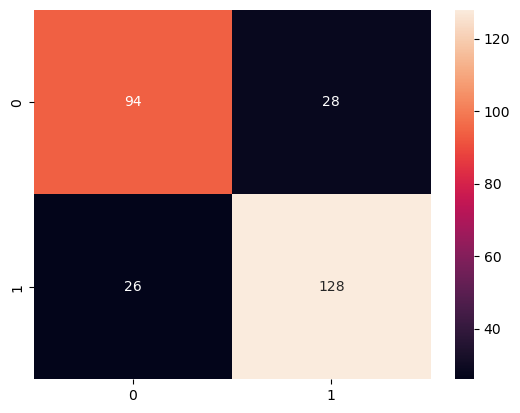

In [29]:
sns.heatmap(metrics.confusion_matrix(y_test,y_pred), annot = True, fmt = 'd')
plt.show()

In [30]:
print(metrics.classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.78      0.77      0.78       122
           1       0.82      0.83      0.83       154

    accuracy                           0.80       276
   macro avg       0.80      0.80      0.80       276
weighted avg       0.80      0.80      0.80       276



In [31]:
# Choosing a K value

error_rate = []

# Will take some time:
for i in range(1,40):
    knn = KNeighborsClassifier(n_neighbors = i)
    knn.fit(X_train,y_train)
    pred_i = knn.predict(X_test)
    error_rate.append(np.mean(pred_i != y_test))

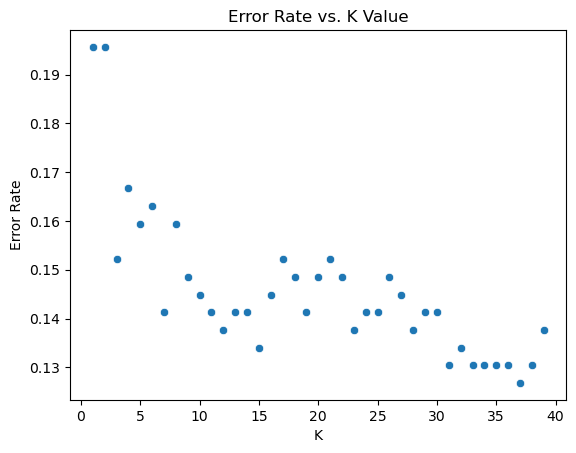

In [32]:
sns.scatterplot(x = range(1,40), y = error_rate)
plt.title('Error Rate vs. K Value')
plt.xlabel('K')
plt.ylabel('Error Rate')
plt.show()

WITH K=1


              precision    recall  f1-score   support

           0       0.78      0.77      0.78       122
           1       0.82      0.83      0.83       154

    accuracy                           0.80       276
   macro avg       0.80      0.80      0.80       276
weighted avg       0.80      0.80      0.80       276



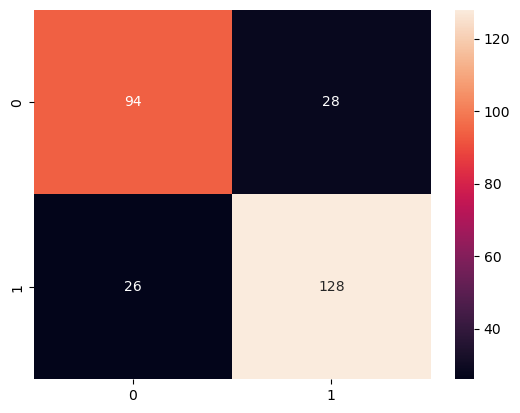

r2 score of our model is : 0.2038461538461538


In [33]:
# Here we can see that around K = 37, the error rate falls below 0.13. Let's retrain the model with K = 37 and Check the accuracy
# Retrain the model with K = 37
# Firstly, a quick comparison to our original K=1 model

knn = KNeighborsClassifier(n_neighbors=1)

knn.fit(X_train,y_train)
pred = knn.predict(X_test)

print('WITH K=1')
print('\n')
print(metrics.classification_report(y_test,pred))
sns.heatmap(metrics.confusion_matrix(y_test,y_pred), annot = True, fmt = 'd')
plt.show()

print('r2 score of our model is :', metrics.r2_score(pred, y_test))

WITH K=37


              precision    recall  f1-score   support

           0       0.87      0.84      0.85       122
           1       0.88      0.90      0.89       154

    accuracy                           0.87       276
   macro avg       0.87      0.87      0.87       276
weighted avg       0.87      0.87      0.87       276



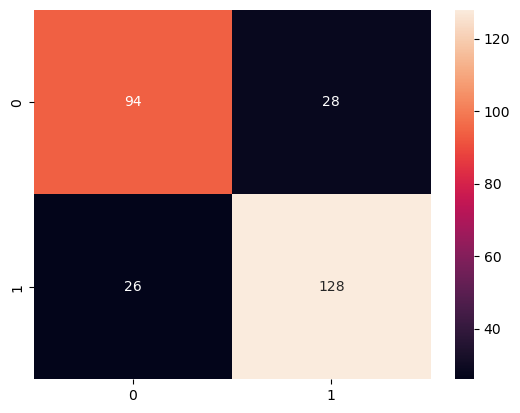

r2 score of our model is : 0.48295241663544397


In [34]:
# Now with K = 37

knn = KNeighborsClassifier(n_neighbors=37)

knn.fit(X_train,y_train)
pred = knn.predict(X_test)

print('WITH K=37')
print('\n')
print(metrics.classification_report(y_test,pred))
sns.heatmap(metrics.confusion_matrix(y_test,y_pred), annot = True, fmt = 'd')
plt.show()

print('r2 score of our model is :', metrics.r2_score(pred, y_test))

## 3: SVM 

### Drinking Water Potability

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:
df = pd.read_csv('Downloads/water_potability.csv')

In [37]:
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [39]:
df.describe()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


In [40]:
df.isna().sum()

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

In [41]:
for i in df.columns.tolist():
    df[i].fillna(df[i].mean(), inplace = True)

C:\Users\varsh\AppData\Local\Temp\ipykernel_9820\3083282573.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[i].fillna(df[i].mean(), inplace = True)


In [42]:
df.isna().sum()

ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64

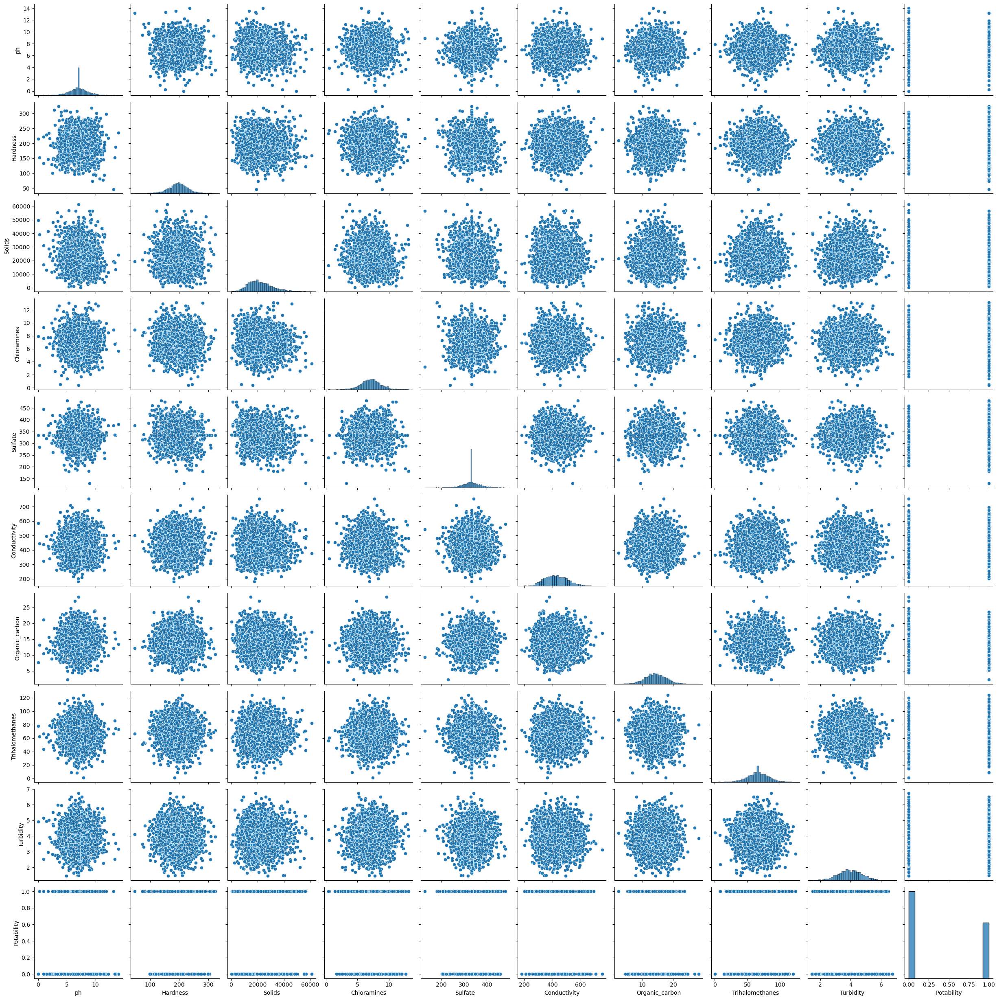

In [43]:
sns.pairplot(df)
plt.show()

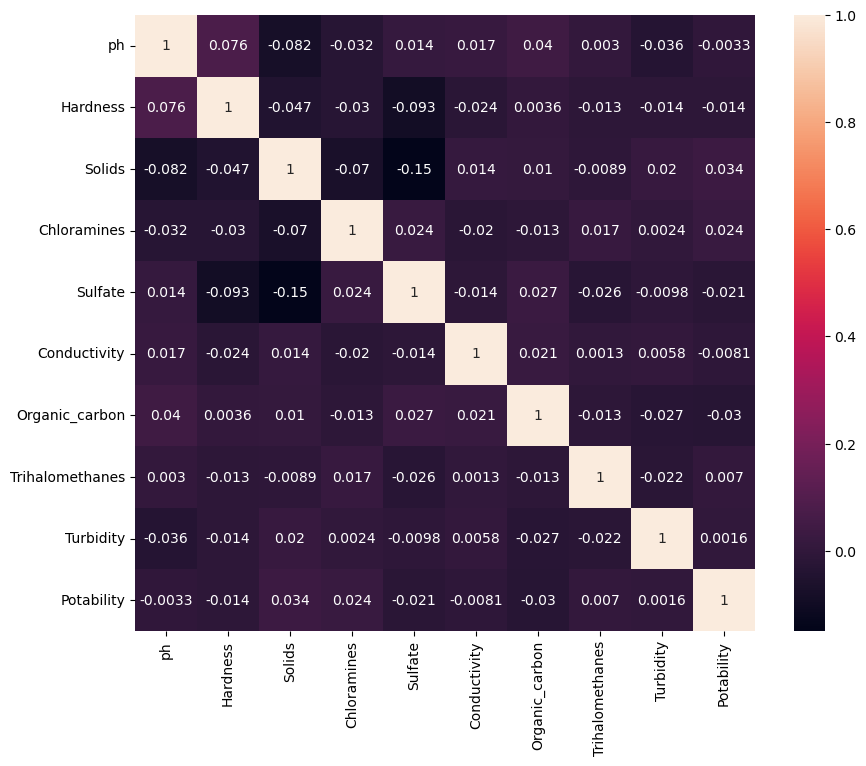

In [44]:
plt.figure(figsize = (10,8))
sns.heatmap(df.corr(), annot = True)
plt.show()

In [45]:
X = df.drop(columns = ['Potability'])
y = df['Potability']

In [46]:
from sklearn.preprocessing import StandardScaler

In [47]:
scaler = StandardScaler()

In [48]:
xcolumns = X.columns

In [49]:
X = scaler.fit_transform(X)

In [50]:
X = pd.DataFrame(X, columns = xcolumns)

In [51]:
X.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
0,-6.043133e-16,0.259195,-0.139471,0.112415,9.613574e-01,1.708954,-1.180651,1.306149,-1.286298
1,-2.289339e+00,-2.036414,-0.385987,-0.307694,3.145987e-15,2.062575,0.270597,-0.638480,0.684218
2,6.928678e-01,0.847665,-0.240047,1.360594,3.145987e-15,-0.094032,0.781117,0.001509,-1.167365
3,8.409504e-01,0.547651,0.000493,0.592008,6.395190e-01,-0.778830,1.255134,2.152874,0.848412
4,1.368569e+00,-0.464429,-0.460249,-0.363698,-6.541765e-01,-0.343939,-0.824357,-2.181599,0.138786


In [52]:
from sklearn.model_selection import train_test_split

In [53]:
X_train, X_test, y_train, y_test = train_test_split(X,y , test_size = 0.3, random_state = 100)

In [54]:
X_train.shape

(2293, 9)

In [55]:
X_test.shape

(983, 9)

In [56]:
from sklearn.svm import SVC # support vector classification

In [57]:
model = SVC()

In [58]:
model.fit(X_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [59]:
model.score(X_train,y_train)

0.7313563017880506

In [60]:
y_pred = model.predict(X_test)

In [61]:
y_pred

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,

In [62]:
from sklearn import metrics

In [63]:
metrics.accuracy_score(y_test, y_pred)

0.6734486266531028

In [64]:
metrics.confusion_matrix(y_test,y_pred)

array([[561,  35],
       [286, 101]])

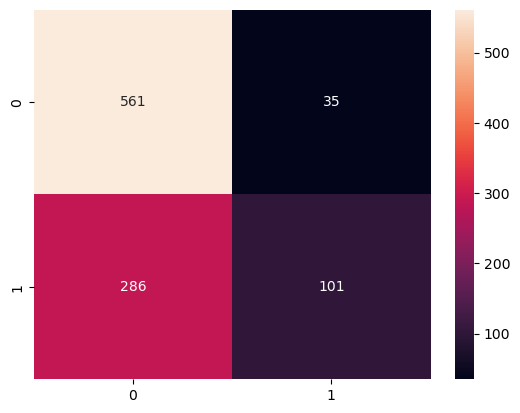

In [65]:
sns.heatmap(metrics.confusion_matrix(y_test,y_pred), annot = True, fmt = 'd')
plt.show()

In [66]:
print(metrics.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.66      0.94      0.78       596
           1       0.74      0.26      0.39       387

    accuracy                           0.67       983
   macro avg       0.70      0.60      0.58       983
weighted avg       0.69      0.67      0.62       983



## 4: NAIVE BAYES 

### Glass Classification

In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [68]:
df = pd.read_csv('Downloads/glass.csv')

In [69]:
df.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


In [71]:
df.describe()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009,2.780374
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439,2.103739
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000,1.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000,2.000000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000,3.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000


In [72]:
df.isna().sum()

RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

C:\Users\varsh\AppData\Local\Temp\ipykernel_9820\4112472445.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x = df['Type'],palette='husl')


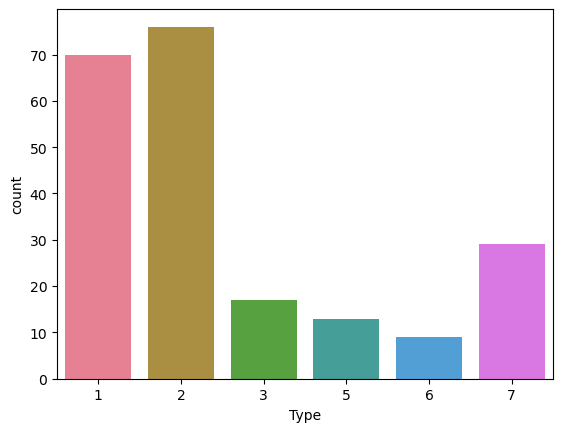

In [76]:
sns.countplot(x = df['Type'],palette='husl')
plt.show()

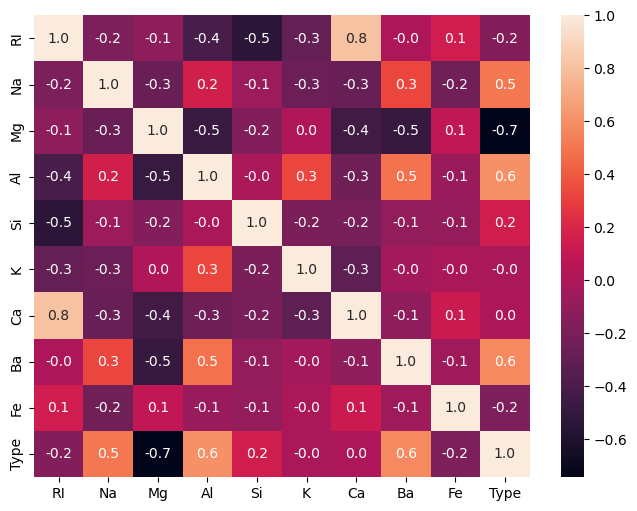

In [77]:
plt.figure(figsize = (8,6))
sns.heatmap(df.corr(), annot = True, fmt = '.1f')
plt.show()

In [78]:
X = df.drop(columns = ['Type'])
y = df['Type']

In [79]:
from sklearn.preprocessing import StandardScaler

In [80]:
scaler = StandardScaler()

In [81]:
xcolumns = X.columns

In [82]:
X = scaler.fit_transform(X)

In [83]:
X = pd.DataFrame(X, columns = xcolumns)

In [84]:
X.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
0,0.872868,0.284953,1.254639,-0.692442,-1.127082,-0.671705,-0.145766,-0.352877,-0.586451
1,-0.249333,0.591817,0.636168,-0.170460,0.102319,-0.026213,-0.793734,-0.352877,-0.586451
2,-0.721318,0.149933,0.601422,0.190912,0.438787,-0.164533,-0.828949,-0.352877,-0.586451
3,-0.232831,-0.242853,0.698710,-0.310994,-0.052974,0.112107,-0.519052,-0.352877,-0.586451
4,-0.312045,-0.169205,0.650066,-0.411375,0.555256,0.081369,-0.624699,-0.352877,-0.586451


In [85]:
from sklearn.model_selection import train_test_split

In [86]:
X_train, X_test, y_train, y_test = train_test_split(X,y , test_size = 0.25, random_state = 100)

In [87]:
from sklearn.naive_bayes import GaussianNB # bernouli, multinomialNB

In [88]:
model = GaussianNB()

In [89]:
model.fit(X_train, y_train)

,priors,None
,var_smoothing,1e-09


In [90]:
model.score(X_train, y_train)

0.56875

In [91]:
y_pred = model.predict(X_test)

In [92]:
y_pred 

array([1, 7, 1, 1, 5, 1, 3, 1, 6, 6, 1, 2, 7, 3, 1, 1, 2, 1, 1, 1, 5, 7,
       3, 7, 1, 1, 7, 1, 1, 3, 6, 1, 1, 1, 1, 7, 3, 1, 1, 1, 1, 2, 1, 3,
       1, 3, 1, 7, 3, 7, 1, 2, 1, 6])

In [93]:
from sklearn import metrics

In [94]:
metrics.accuracy_score(y_test, y_pred)

0.3888888888888889

In [95]:
metrics.confusion_matrix(y_test, y_pred)

array([[10,  0,  3,  0,  0,  0],
       [16,  0,  4,  1,  2,  0],
       [ 2,  0,  1,  0,  0,  0],
       [ 0,  4,  0,  1,  0,  1],
       [ 0,  0,  0,  0,  2,  0],
       [ 0,  0,  0,  0,  0,  7]])

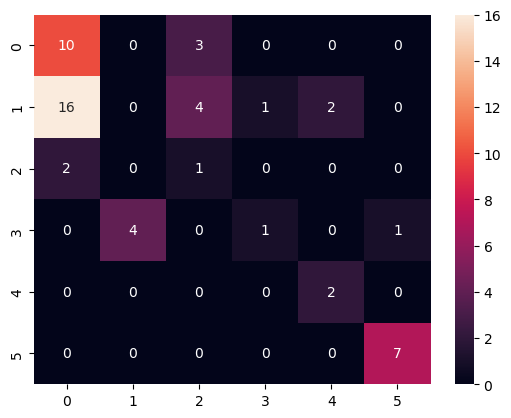

In [96]:
sns.heatmap(metrics.confusion_matrix(y_test,y_pred), annot = True)
plt.show()

In [97]:
print(metrics.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.36      0.77      0.49        13
           2       0.00      0.00      0.00        23
           3       0.12      0.33      0.18         3
           5       0.50      0.17      0.25         6
           6       0.50      1.00      0.67         2
           7       0.88      1.00      0.93         7

    accuracy                           0.39        54
   macro avg       0.39      0.54      0.42        54
weighted avg       0.28      0.39      0.30        54



## 5:DECISION TREE

### Graduate Admission Prediction

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Downloads/admission_predict.csv')

In [3]:
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [4]:
df.tail()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
495,496,332,108,5,4.5,4.0,9.02,1,0.87
496,497,337,117,5,5.0,5.0,9.87,1,0.96
497,498,330,120,5,4.5,5.0,9.56,1,0.93
498,499,312,103,4,4.0,5.0,8.43,0,0.73
499,500,327,113,4,4.5,4.5,9.04,0,0.84


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         500 non-null    int64  
 1   GRE Score          500 non-null    int64  
 2   TOEFL Score        500 non-null    int64  
 3   University Rating  500 non-null    int64  
 4   SOP                500 non-null    float64
 5   LOR                500 non-null    float64
 6   CGPA               500 non-null    float64
 7   Research           500 non-null    int64  
 8   Chance of Admit    500 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 35.3 KB


In [6]:
df.describe()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.00000,500.000000,500.000000,500.00000
mean,250.500000,316.472000,107.192000,3.114000,3.374000,3.48400,8.576440,0.560000,0.72174
std,144.481833,11.295148,6.081868,1.143512,0.991004,0.92545,0.604813,0.496884,0.14114
min,1.000000,290.000000,92.000000,1.000000,1.000000,1.00000,6.800000,0.000000,0.34000
25%,125.750000,308.000000,103.000000,2.000000,2.500000,3.00000,8.127500,0.000000,0.63000
50%,250.500000,317.000000,107.000000,3.000000,3.500000,3.50000,8.560000,1.000000,0.72000
75%,375.250000,325.000000,112.000000,4.000000,4.000000,4.00000,9.040000,1.000000,0.82000
max,500.000000,340.000000,120.000000,5.000000,5.000000,5.00000,9.920000,1.000000,0.97000


In [36]:
df.isna().sum()

GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Admission            0
dtype: int64

In [8]:
# Currently our target variable ranges form 0 to 1. We need to make this a classification problem. Create a new variable named 'Admission' which has values 0 and 1. If Chance of admin < 0.5, Admission = 0. If chance of admit > 0.5, Admission = 1

# Create a function which converts values less than 0.5 to 0 and rest to 1
def zeroone(x):
    if x <= 0.5:
        return 0
    elif x > 0.5:
        return 1

In [9]:
df['Admission'] = df['Chance of Admit '].apply(zeroone)

In [10]:
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Admission
0,1,337,118,4,4.5,4.5,9.65,1,0.92,1
1,2,324,107,4,4.0,4.5,8.87,1,0.76,1
2,3,316,104,3,3.0,3.5,8.00,1,0.72,1
3,4,322,110,3,3.5,2.5,8.67,1,0.80,1
4,5,314,103,2,2.0,3.0,8.21,0,0.65,1


In [11]:
df.drop(columns = ['Chance of Admit ', 'Serial No.'], inplace = True)
df.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Admission
0,337,118,4,4.5,4.5,9.65,1,1
1,324,107,4,4.0,4.5,8.87,1,1
2,316,104,3,3.0,3.5,8.00,1,1
3,322,110,3,3.5,2.5,8.67,1,1
4,314,103,2,2.0,3.0,8.21,0,1


[]

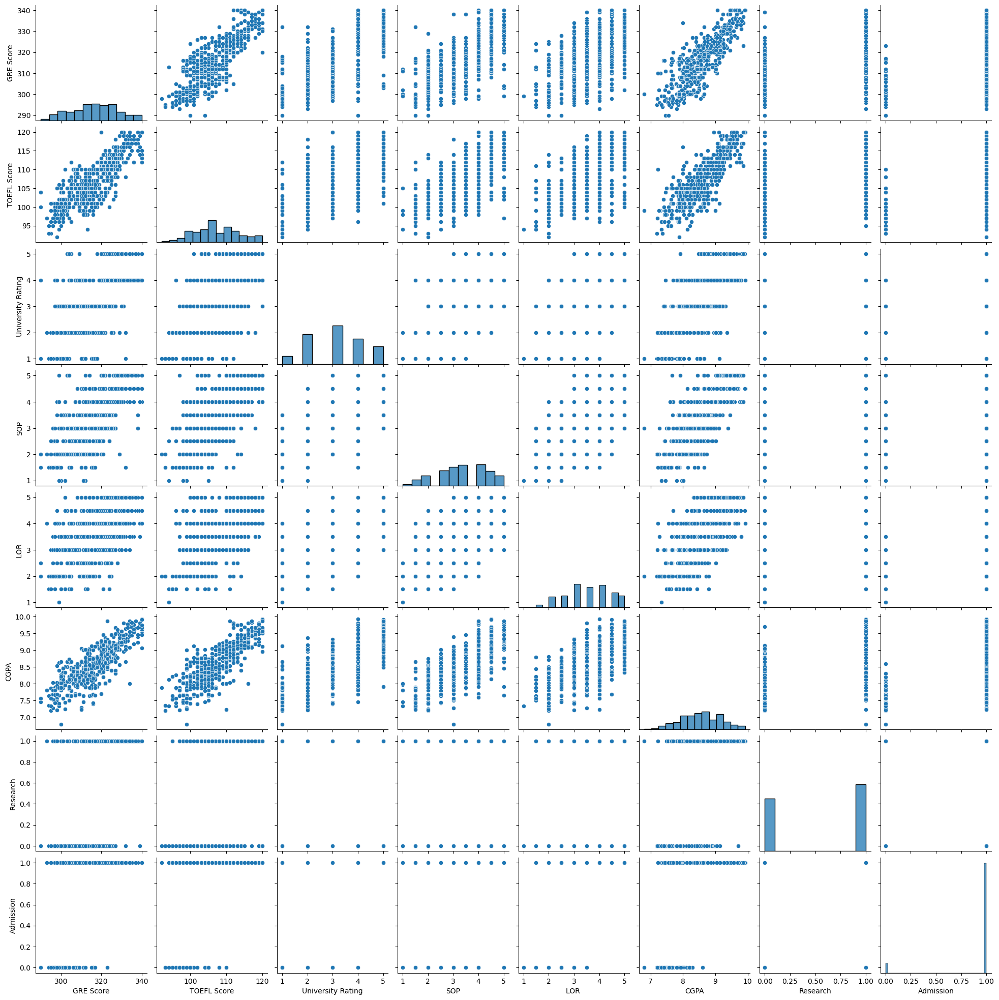

In [12]:
sns.pairplot(df)
plt.plot()

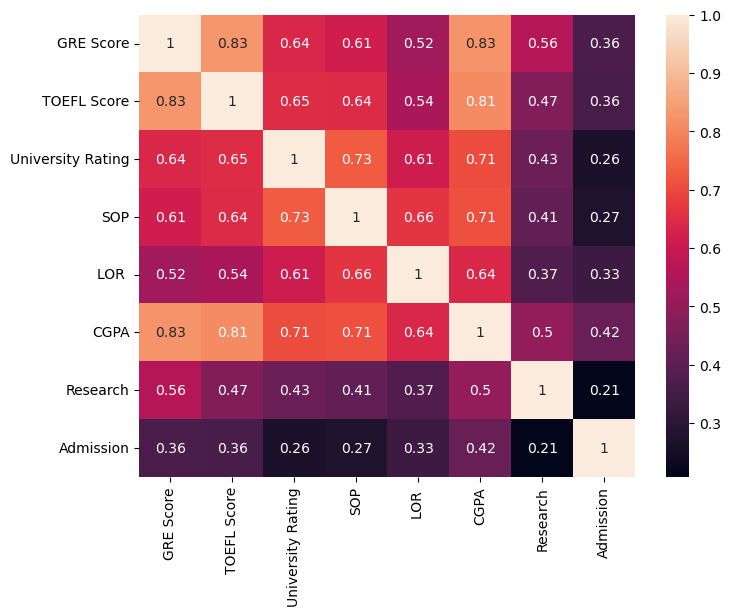

In [13]:
plt.figure(figsize = (8,6))
sns.heatmap(df.corr(), annot = True)
plt.show()

In [14]:
X = df.drop(columns = ['Admission'])
y = df['Admission']

In [15]:
from sklearn.preprocessing import StandardScaler

In [16]:
scaler = StandardScaler()

In [17]:
xcolumns = X.columns

In [18]:
X = scaler.fit_transform(X)

In [19]:
X = pd.DataFrame(X, columns = xcolumns)

In [20]:
X.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
0,1.819238,1.778865,0.775582,1.137360,1.098944,1.776806,0.886405
1,0.667148,-0.031601,0.775582,0.632315,1.098944,0.485859,0.886405
2,-0.041830,-0.525364,-0.099793,-0.377773,0.017306,-0.954043,0.886405
3,0.489904,0.462163,-0.099793,0.127271,-1.064332,0.154847,0.886405
4,-0.219074,-0.689952,-0.975168,-1.387862,-0.523513,-0.606480,-1.128152


In [21]:
from sklearn.model_selection import train_test_split

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 100)

In [23]:
X_train.shape

(400, 7)

In [24]:
X_test.shape

(100, 7)

In [25]:
from sklearn.tree import DecisionTreeClassifier

In [26]:
model = DecisionTreeClassifier()

In [27]:
model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [28]:
model.score(X_train, y_train)

1.0

In [29]:
y_pred = model.predict(X_test)

In [30]:
y_pred

array([1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [31]:
from sklearn import metrics

In [32]:
metrics.accuracy_score(y_test, y_pred)

0.91

In [33]:
metrics.confusion_matrix(y_test, y_pred)

array([[ 3,  2],
       [ 7, 88]])

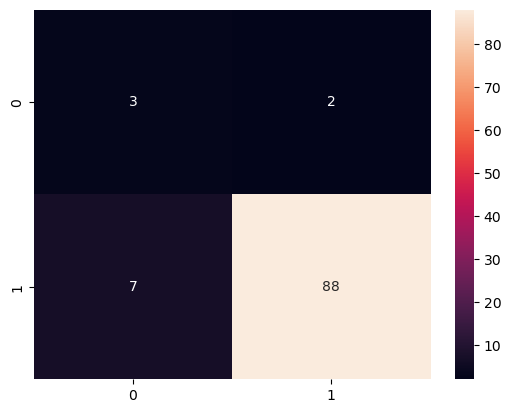

In [34]:
sns.heatmap(metrics.confusion_matrix(y_test, y_pred), annot = True)
plt.show()

In [35]:
print(metrics.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.30      0.60      0.40         5
           1       0.98      0.93      0.95        95

    accuracy                           0.91       100
   macro avg       0.64      0.76      0.68       100
weighted avg       0.94      0.91      0.92       100



## 6: RANDOM FOREST

### Mobile Price Classification

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [38]:
df = pd.read_csv('Downloads/mobile_price.csv')

In [39]:
df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_sc

In [41]:
df.describe()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,...,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,...,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,...,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


In [42]:
df.isna().sum()

battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64

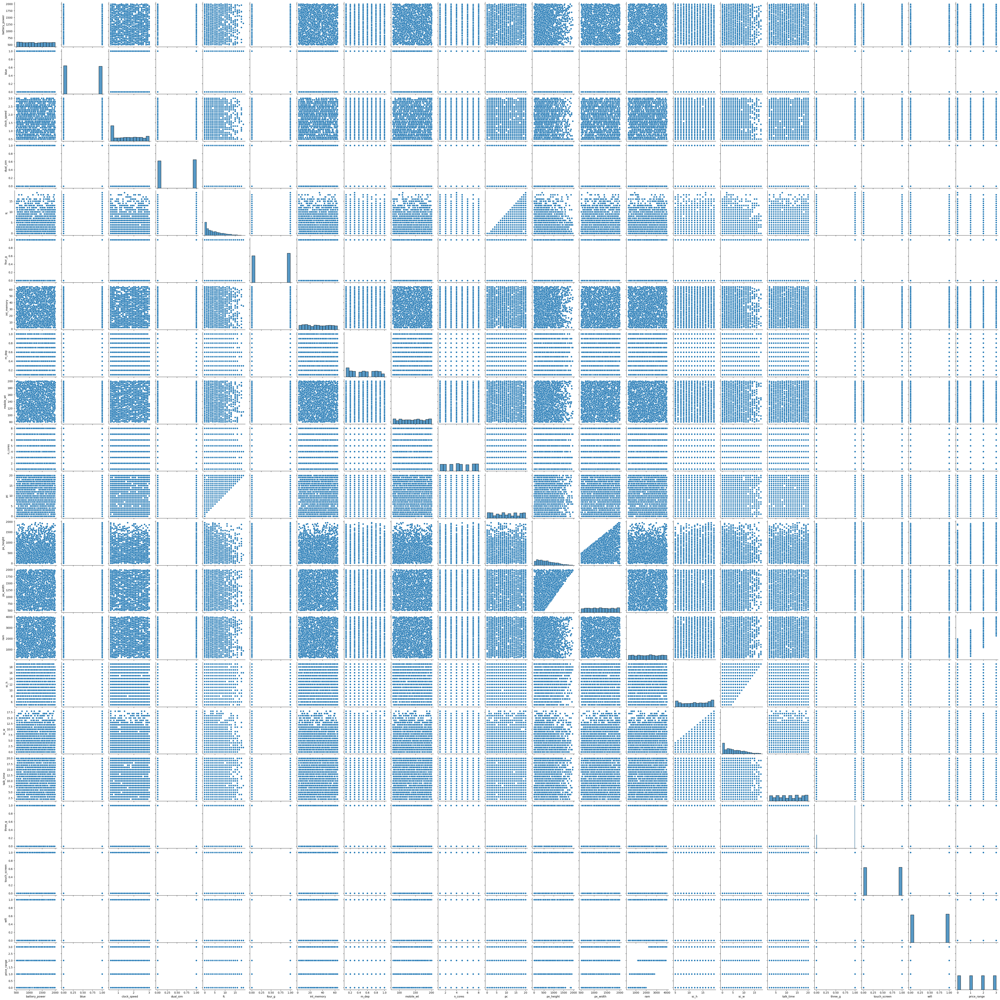

In [43]:
sns.pairplot(df)
plt.show()

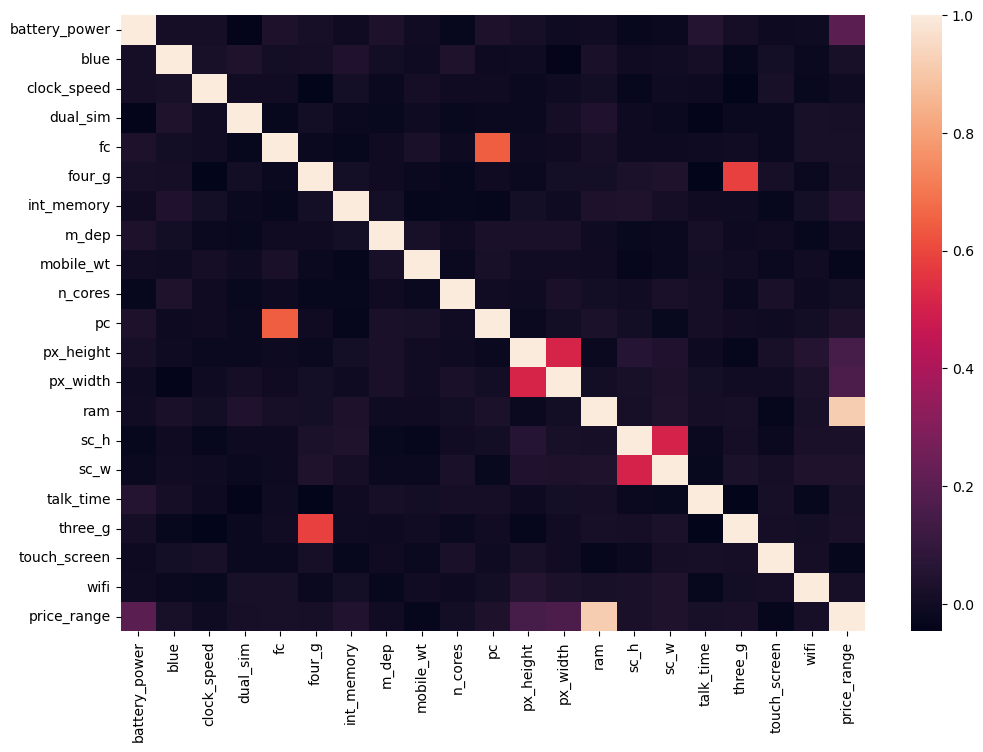

In [44]:
plt.figure(figsize = (12,8))
sns.heatmap(df.corr())
plt.show()

In [45]:
X =  df.drop(columns = ['price_range'])
y = df['price_range']

In [46]:
from sklearn.preprocessing import StandardScaler

In [47]:
scaler = StandardScaler()

In [48]:
xcolumns = X.columns

In [49]:
X = scaler.fit_transform(X)

In [50]:
X = pd.DataFrame(X, columns = xcolumns)

In [51]:
X.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,-0.902597,-0.990050,0.830779,-1.019184,-0.762495,-1.043966,-1.380644,0.340740,1.349249,-1.101971,-1.305750,-1.408949,-1.146784,0.391703,-0.784983,0.283103,1.462493,-1.786861,-1.006018,0.986097
1,-0.495139,1.010051,-1.253064,0.981177,-0.992890,0.957886,1.155024,0.687548,-0.120059,-0.664768,-0.645989,0.585778,1.704465,0.467317,1.114266,-0.635317,-0.734267,0.559641,0.994018,-1.014099
2,-1.537686,1.010051,-1.253064,0.981177,-0.532099,0.957886,0.493546,1.381165,0.134244,0.209639,-0.645989,1.392684,1.074968,0.441498,-0.310171,-0.864922,-0.368140,0.559641,0.994018,-1.014099
3,-1.419319,1.010051,1.198517,-1.019184,-0.992890,-1.043966,-1.215274,1.034357,-0.261339,0.646842,-0.151168,1.286750,1.236971,0.594569,0.876859,0.512708,-0.002014,0.559641,-1.006018,-1.014099
4,1.325906,1.010051,-0.395011,-1.019184,2.002254,0.957886,0.658915,0.340740,0.021220,-1.101971,0.673534,1.268718,-0.091452,-0.657666,-1.022389,-0.864922,0.730240,0.559641,0.994018,-1.014099


In [52]:
from sklearn.model_selection import train_test_split

In [53]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.25, random_state = 100)

In [54]:
# Create random forest model. 
# Let n_estimator = 100

from sklearn.ensemble import RandomForestClassifier

In [55]:
model = RandomForestClassifier(n_estimators= 100)

In [56]:
model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [57]:
model.score(X_train, y_train)

1.0

In [59]:
y_pred = model.predict(X_test)

In [60]:
y_pred

array([0, 1, 1, 3, 2, 3, 3, 2, 3, 1, 0, 1, 3, 3, 0, 2, 2, 3, 2, 0, 0, 3,
       1, 0, 0, 1, 3, 0, 1, 2, 0, 3, 0, 1, 0, 2, 3, 2, 1, 3, 3, 3, 0, 0,
       3, 3, 2, 0, 1, 2, 3, 2, 3, 2, 1, 3, 1, 3, 1, 0, 3, 2, 3, 0, 3, 0,
       0, 3, 3, 2, 0, 1, 2, 0, 2, 3, 0, 3, 2, 3, 1, 0, 2, 0, 2, 2, 1, 2,
       3, 3, 3, 3, 3, 2, 0, 2, 3, 0, 1, 1, 0, 0, 2, 3, 2, 0, 0, 1, 1, 1,
       0, 1, 3, 2, 0, 3, 1, 3, 1, 1, 3, 1, 0, 2, 3, 2, 3, 2, 0, 3, 1, 0,
       1, 2, 3, 1, 3, 2, 0, 0, 3, 0, 3, 3, 1, 2, 2, 2, 0, 2, 0, 3, 1, 2,
       1, 0, 2, 3, 1, 1, 3, 2, 3, 0, 1, 3, 0, 3, 3, 0, 2, 1, 2, 1, 2, 1,
       2, 1, 3, 0, 0, 2, 1, 0, 0, 3, 2, 2, 3, 2, 2, 1, 1, 1, 2, 2, 3, 1,
       2, 1, 3, 1, 2, 1, 3, 0, 1, 3, 3, 2, 0, 1, 2, 0, 0, 2, 3, 0, 1, 3,
       0, 3, 0, 0, 1, 1, 2, 3, 2, 0, 1, 2, 0, 1, 1, 3, 3, 3, 2, 0, 1, 3,
       2, 1, 0, 2, 2, 1, 2, 1, 1, 2, 3, 1, 3, 2, 1, 1, 2, 3, 1, 3, 2, 2,
       2, 2, 3, 1, 2, 1, 0, 3, 2, 0, 2, 1, 1, 3, 2, 1, 2, 1, 3, 1, 0, 2,
       3, 0, 0, 1, 2, 2, 1, 2, 2, 0, 2, 3, 0, 3, 3,

In [61]:
from sklearn import metrics

In [62]:
metrics.accuracy_score(y_test, y_pred)

0.866

In [63]:
metrics.confusion_matrix(y_test, y_pred)

array([[127,   8,   0,   0],
       [ 11,  97,  15,   0],
       [  0,  19,  93,   6],
       [  0,   0,   8, 116]])

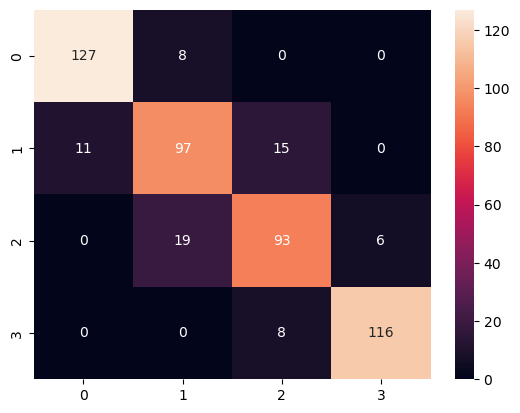

In [64]:
sns.heatmap(metrics.confusion_matrix(y_test,y_pred), annot = True, fmt = 'd')
plt.show()

In [65]:
print(metrics.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.94      0.93       135
           1       0.78      0.79      0.79       123
           2       0.80      0.79      0.79       118
           3       0.95      0.94      0.94       124

    accuracy                           0.87       500
   macro avg       0.86      0.86      0.86       500
weighted avg       0.87      0.87      0.87       500



## 7: AdaBoost

### Telco-Customer-Churn prediction

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Downloads/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
def churn(x):
    if x == 'No':
        return 0
    else:
        return 1

In [10]:
df['Churn'] = df['Churn'].apply(churn)

In [11]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,0
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,0
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,0
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,1


In [12]:
df['Churn'].unique()

array([0, 1])

In [13]:
df.drop(['customerID'], axis=1, inplace=True)

In [14]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [16]:
from sklearn.preprocessing import LabelEncoder

In [17]:
le = LabelEncoder()

for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = le.fit_transform(df[col].astype(str))

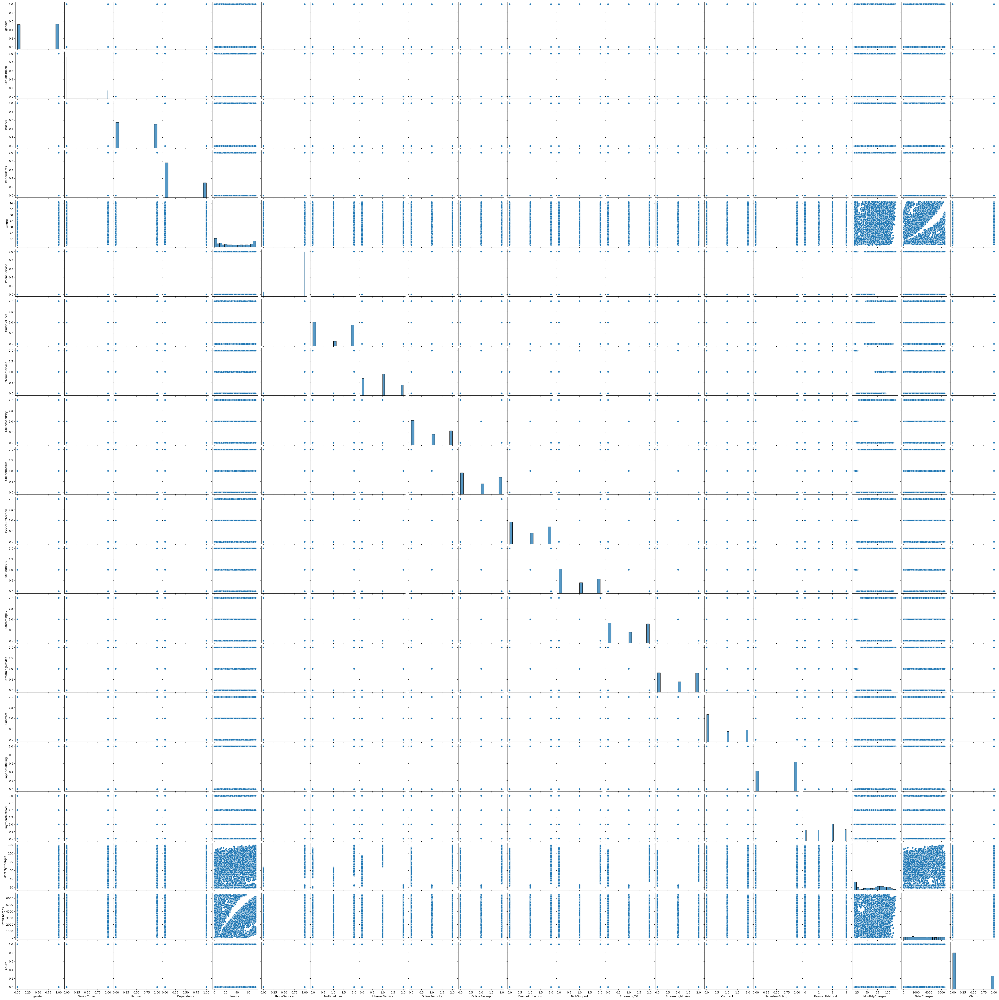

In [19]:
sns.pairplot(df)
plt.show()

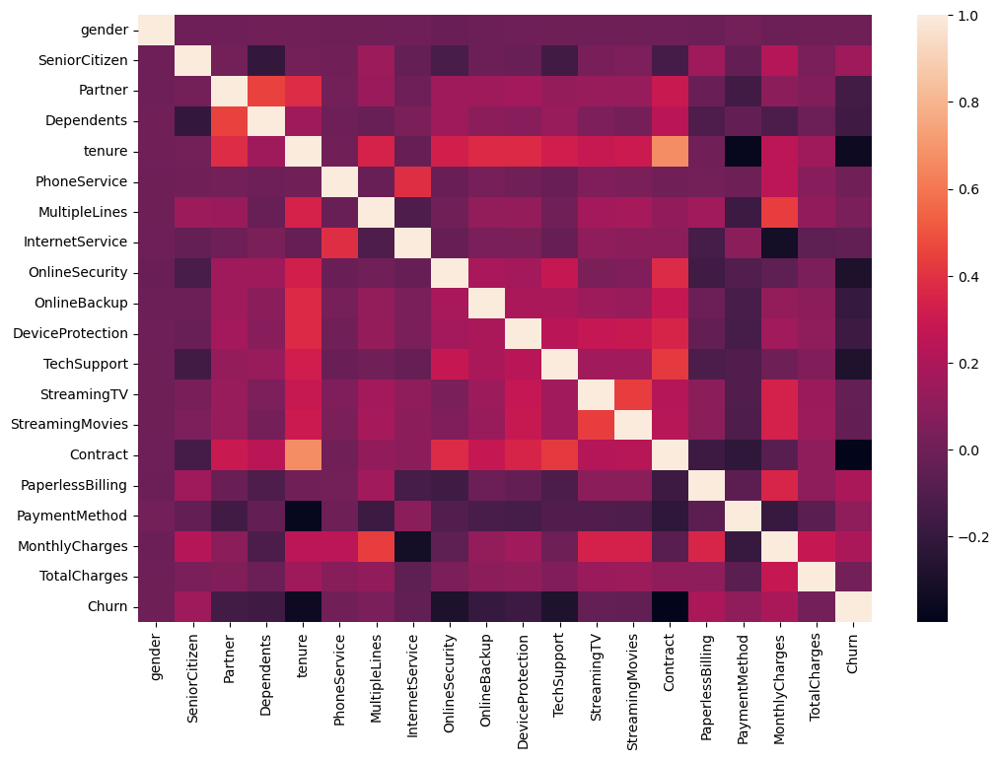

In [20]:
plt.figure(figsize = (12,8))
sns.heatmap(df.corr())
plt.show()

In [23]:
X = df.drop('Churn', axis=1)
y = df['Churn']

In [24]:
from sklearn.preprocessing import StandardScaler

In [25]:
scaler = StandardScaler()

In [26]:
xcolumns = X.columns

In [27]:
X = scaler.fit_transform(X)

In [28]:
X = pd.DataFrame(X, columns = xcolumns)

In [29]:
X.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,-1.009559,-0.439916,1.034530,-0.654012,-1.277445,-3.054010,0.062723,-1.183234,-0.918838,1.242550,-1.027910,-0.925262,-1.113495,-1.121405,-0.828207,0.829798,0.398558,-1.160323,-0.398608
1,0.990532,-0.439916,-0.966622,-0.654012,0.066327,0.327438,-0.991588,-1.183234,1.407321,-1.029919,1.245111,-0.925262,-1.113495,-1.121405,0.371271,-1.205113,1.334863,-0.259629,-0.948762
2,0.990532,-0.439916,-0.966622,-0.654012,-1.236724,0.327438,-0.991588,-1.183234,1.407321,1.242550,-1.027910,-0.925262,-1.113495,-1.121405,-0.828207,0.829798,1.334863,-0.362660,-1.641883
3,0.990532,-0.439916,-0.966622,-0.654012,0.514251,-3.054010,0.062723,-1.183234,1.407321,-1.029919,1.245111,1.396299,-1.113495,-1.121405,0.371271,-1.205113,-1.474052,-0.746535,-0.983710
4,-1.009559,-0.439916,-0.966622,-0.654012,-1.236724,0.327438,-0.991588,0.172250,-0.918838,-1.029919,-1.027910,-0.925262,-1.113495,-1.121405,-0.828207,0.829798,0.398558,0.197365,-1.235224


In [30]:
from sklearn.model_selection import train_test_split

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.25, random_state = 100)

In [32]:
from sklearn.ensemble import AdaBoostClassifier

In [33]:
model = AdaBoostClassifier(n_estimators=100,learning_rate=1.0,random_state=42)

In [34]:
model.fit(X_train, y_train)

,estimator,None
,n_estimators,100
,learning_rate,1.0
,algorithm,'deprecated'
,random_state,42


In [35]:
model.score(X_train, y_train)

0.8131389625141991

In [36]:
y_pred = model.predict(X_test)

In [37]:
y_pred 

array([0, 0, 0, ..., 1, 0, 0], shape=(1761,))

In [38]:
from sklearn import metrics

In [39]:
metrics.accuracy_score(y_test, y_pred)

0.7762634866553095

In [40]:
metrics.confusion_matrix(y_test, y_pred)

array([[1113,  159],
       [ 235,  254]])

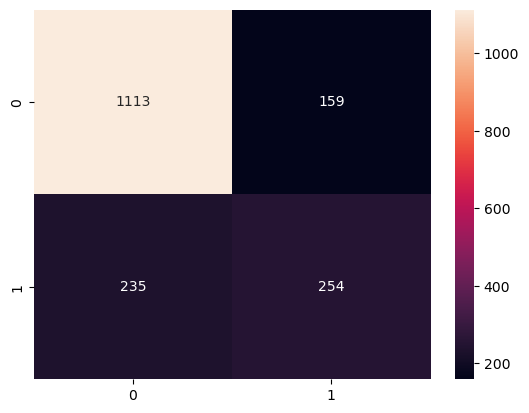

In [41]:
sns.heatmap(metrics.confusion_matrix(y_test,y_pred), annot = True, fmt = 'd')
plt.show()

In [42]:
print(metrics.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.88      0.85      1272
           1       0.62      0.52      0.56       489

    accuracy                           0.78      1761
   macro avg       0.72      0.70      0.71      1761
weighted avg       0.77      0.78      0.77      1761



## 8: XGBoost

### creditcard prediction

In [43]:
pip install xgboost

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.8/101.7 MB 5.8 MB/s eta 0:00:18
    --------------------------------------- 2.4/101.7 MB 9.3 MB/s eta 0:00:11
   - -------------------------------------- 3.7/101.7 MB 8.3 MB/s eta 0:00:12
   -- ------------------------------------- 5.5/101.7 MB 7.6 MB/s eta 0:00:13
   -- ------------------------------------- 6.6/101.7 MB 6.8 MB/s eta 0:00:15
   -- ------------------------------------- 7.6/101.7 MB 6.4 MB/s eta 0:00:15
   --- ------------------------------------ 8.1/101.7 MB 6.0 MB/s eta 0:00:16
   --- ------------------------------------ 8.4/101.7 MB 5.7 MB/s eta 0:00:17
   --- ------------------------------------ 8.7/101.7 MB 5.1 MB/s eta 0:00:19
   --- ------------------------------------ 8.9/101.7 MB 4.8 MB/s eta 0:00:20
   --- ------------------------------------ 9.4/101.7 MB 4.3 MB/s eta 0:00:22


In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [45]:
df = pd.read_csv('Downloads/creditcard.csv/creditcard.csv')

In [46]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [47]:
df.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [49]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [50]:
df.isna().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [51]:
sns.pairplot(df)
plt.show()

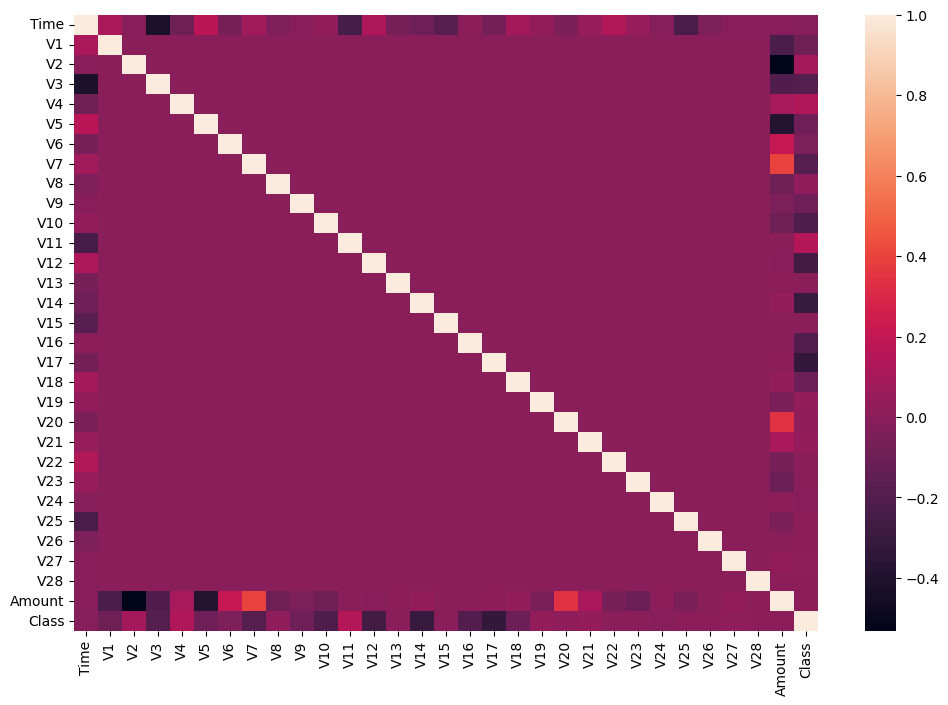

In [52]:
plt.figure(figsize = (12,8))
sns.heatmap(df.corr())
plt.show()

In [53]:
X = df.drop("Class", axis=1)
y = df["Class"]

In [54]:
from sklearn.preprocessing import StandardScaler

In [55]:
scaler = StandardScaler()

In [56]:
xcolumns = X.columns

In [57]:
X = scaler.fit_transform(X)

In [58]:
X = pd.DataFrame(X, columns = xcolumns)

In [59]:
X.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,-1.996583,-0.694242,-0.044075,1.672773,0.973366,-0.245117,0.347068,0.193679,0.082637,0.331128,...,0.326118,-0.024923,0.382854,-0.176911,0.110507,0.246585,-0.392170,0.330892,-0.063781,0.244964
1,-1.996583,0.608496,0.161176,0.109797,0.316523,0.043483,-0.061820,-0.063700,0.071253,-0.232494,...,-0.089611,-0.307377,-0.880077,0.162201,-0.561131,0.320694,0.261069,-0.022256,0.044608,-0.342475
2,-1.996562,-0.693500,-0.811578,1.169468,0.268231,-0.364572,1.351454,0.639776,0.207373,-1.378675,...,0.680975,0.337632,1.063358,1.456320,-1.138092,-0.628537,-0.288447,-0.137137,-0.181021,1.160686
3,-1.996562,-0.493325,-0.112169,1.182516,-0.609727,-0.007469,0.936150,0.192071,0.316018,-1.262503,...,-0.269855,-0.147443,0.007267,-0.304777,-1.941027,1.241904,-0.460217,0.155396,0.186189,0.140534
4,-1.996541,-0.591330,0.531541,1.021412,0.284655,-0.295015,0.071999,0.479302,-0.226510,0.744326,...,0.529939,-0.012839,1.100011,-0.220123,0.233250,-0.395202,1.041611,0.543620,0.651816,-0.073403


In [60]:
from sklearn.model_selection import train_test_split

In [61]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.25, random_state = 100)

In [62]:
from xgboost import XGBClassifier

In [63]:
model = XGBClassifier(n_estimators=200,learning_rate=0.1,max_depth=6,random_state=42)

In [64]:
model.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [65]:
model.score(X_train, y_train)

1.0

In [66]:
y_pred = model.predict(X_test)

In [67]:
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(71202,))

In [68]:
from sklearn import metrics

In [69]:
metrics.accuracy_score(y_test, y_pred)

0.9994663071262043

In [70]:
metrics.confusion_matrix(y_test, y_pred)

array([[71072,     8],
       [   30,    92]])

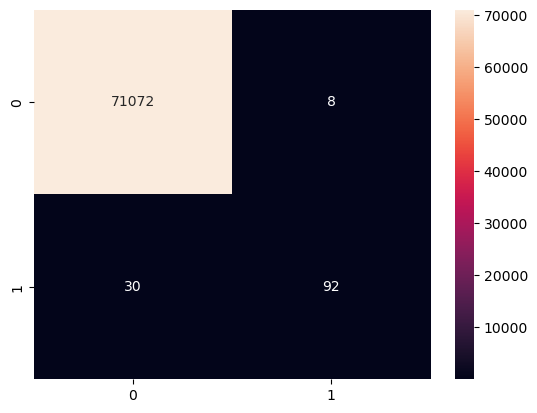

In [71]:
sns.heatmap(metrics.confusion_matrix(y_test,y_pred), annot = True, fmt = 'd')
plt.show()

In [72]:
print(metrics.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     71080
           1       0.92      0.75      0.83       122

    accuracy                           1.00     71202
   macro avg       0.96      0.88      0.91     71202
weighted avg       1.00      1.00      1.00     71202



# UNSUPERVISED LEARNING

## A: CLUSTERING

# 9: K-MEANS CLUSTERING

### Mall Customers Clustering

In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [74]:
df = pd.read_csv('Downloads/Mall_Customers.csv')

In [75]:
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [76]:
df.tail()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18
199,200,Male,30,137,83


In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [78]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [79]:
df.isna().sum()

CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [80]:
df['Genre'].unique()

array(['Male', 'Female'], dtype=object)

In [81]:
def gender(x):
    if x == "Male":
        return 0
    else:
        return 1

In [82]:
df['Genre'] = df['Genre'].apply(gender)

In [83]:
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,0,19,15,39
1,2,0,21,15,81
2,3,1,20,16,6
3,4,1,23,16,77
4,5,1,31,17,40


In [84]:
df.drop(columns = ['CustomerID'], inplace = True)

In [85]:
df.head()

,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,0,19,15,39
1,0,21,15,81
2,1,20,16,6
3,1,23,16,77
4,1,31,17,40


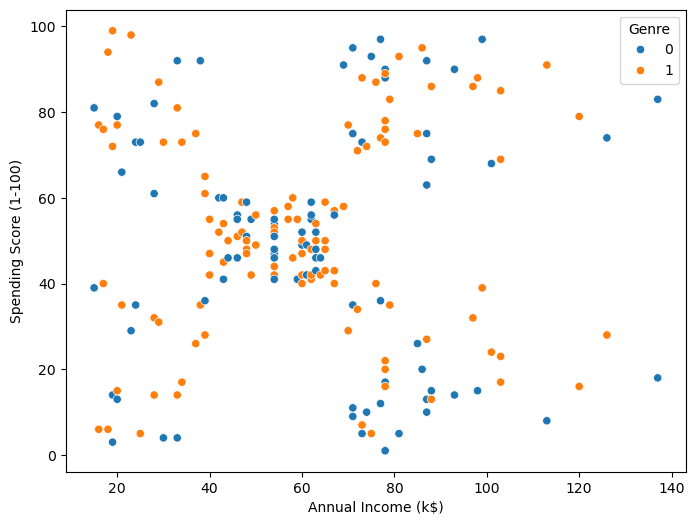

In [86]:
plt.figure(figsize = (8,6))
sns.scatterplot(x = 'Annual Income (k$)',  y = 'Spending Score (1-100)', data = df, hue = 'Genre')
plt.show()

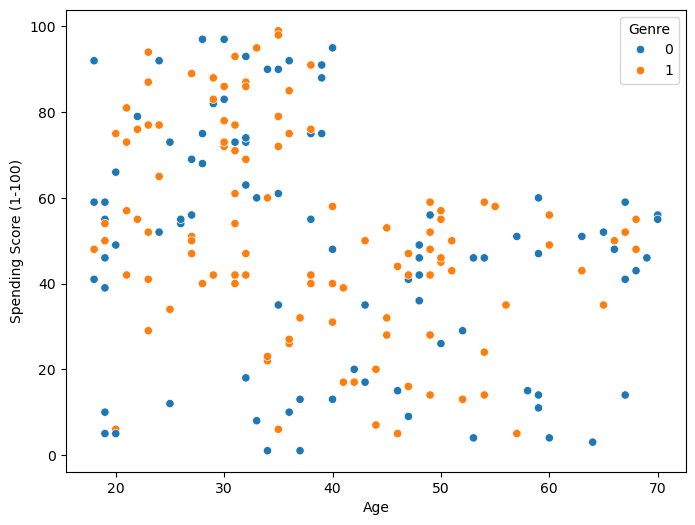

In [87]:
plt.figure(figsize = (8,6))
sns.scatterplot(data = df, x = 'Age', y = 'Spending Score (1-100)', hue = 'Genre')
plt.show()

In [88]:
from sklearn.cluster import KMeans

In [89]:
model = KMeans(n_clusters=3)

In [90]:
clusters = model.fit_predict(df)
clusters

C:\Users\varsh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1], dtype=int32)

In [91]:
df['Clusters'] = clusters

In [92]:
df.head()

,Genre,Age,Annual Income (k$),Spending Score (1-100),Clusters
0,0,19,15,39,0
1,0,21,15,81,0
2,1,20,16,6,0
3,1,23,16,77,0
4,1,31,17,40,0


In [93]:
df['Clusters'].unique()

array([0, 1, 2], dtype=int32)

In [94]:
# Assign each cluster to a new Dataframe

df0 = df[df['Clusters'] == 0]
df1 = df[df['Clusters'] == 1]
df2 = df[df['Clusters'] == 2]

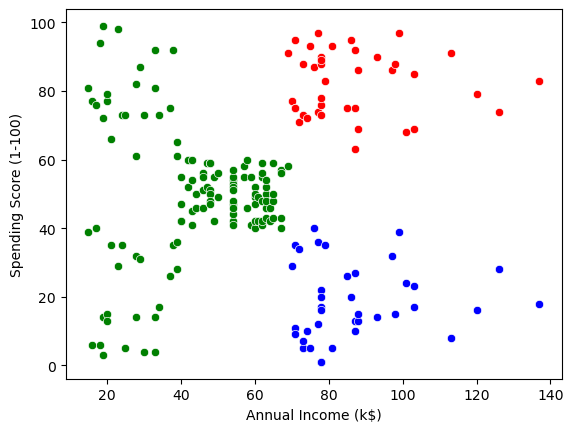

In [96]:
sns.scatterplot(data = df0, x = 'Annual Income (k$)', y = 'Spending Score (1-100)', color = 'green')
sns.scatterplot(data = df1, x = 'Annual Income (k$)', y = 'Spending Score (1-100)', color = 'red')
sns.scatterplot(data = df2, x = 'Annual Income (k$)', y = 'Spending Score (1-100)', color = 'blue')
plt.show()

## HIERARCHICAL CLUSTERING

# 10: AGGLOMERATIVE CLUSTERING

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("Downloads/Mall_Customers (1).csv")

In [3]:
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
#  Select Features
# We use:

# * Annual Income
# * Spending Score

X = df.iloc[:, [3,4]].values

In [7]:
from scipy.cluster.hierarchy import dendrogram, linkage

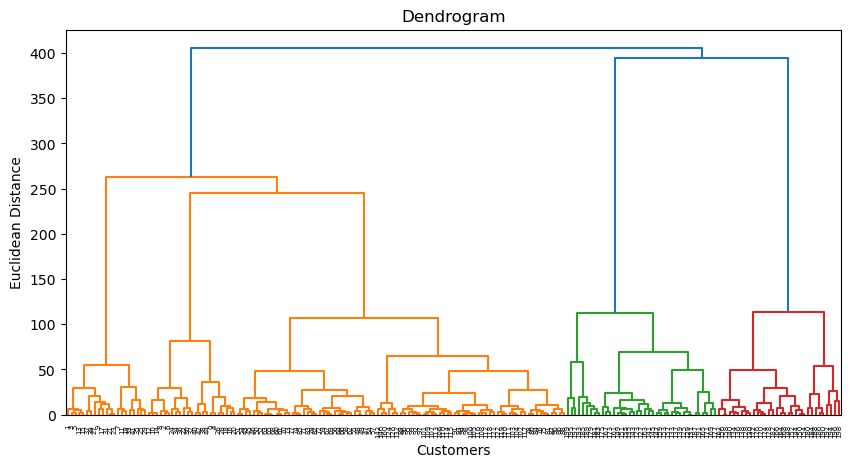

In [8]:
# Create Dendrogram
# A dendrogram helps determine the optimal number of clusters.

plt.figure(figsize=(10,5))

dendrogram(
    linkage(X, method='ward')
)

plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Euclidean Distance")
plt.show()

In [9]:
from sklearn.cluster import AgglomerativeClustering

In [10]:
hc = AgglomerativeClustering(n_clusters=5,metric='euclidean',linkage='ward')

In [11]:
y_pred = hc.fit_predict(X)

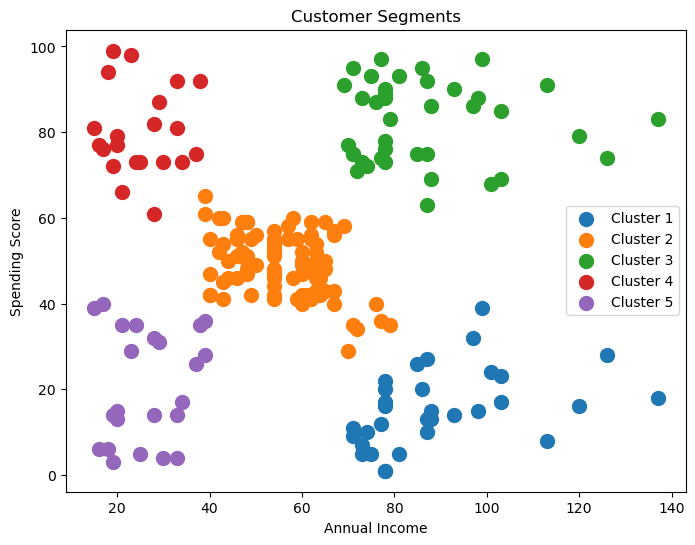

In [13]:
plt.figure(figsize=(8,6))

plt.scatter(X[y_pred==0,0], X[y_pred==0,1],
            s=100, label='Cluster 1')

plt.scatter(X[y_pred==1,0], X[y_pred==1,1],
            s=100, label='Cluster 2')

plt.scatter(X[y_pred==2,0], X[y_pred==2,1],
            s=100, label='Cluster 3')

plt.scatter(X[y_pred==3,0], X[y_pred==3,1],
            s=100, label='Cluster 4')

plt.scatter(X[y_pred==4,0], X[y_pred==4,1],
            s=100, label='Cluster 5')

plt.title("Customer Segments")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.legend()
plt.show()

# 11: DBSCAN

In [14]:
pip install hdbscan

   ---------------------------------------- 0.0/1.9 MB ? eta -:--:--
   --------------------- ------------------ 1.0/1.9 MB 11.3 MB/s eta 0:00:01
   ---------------------------------------- 1.9/1.9 MB 10.9 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [16]:
df = pd.read_csv("Downloads/Mall_Customers (1).csv")

In [17]:
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [18]:
X = df[['Annual Income (k$)',
        'Spending Score (1-100)']]

In [19]:
from sklearn.preprocessing import StandardScaler

In [20]:
scaler = StandardScaler()

In [21]:
X_scaled = scaler.fit_transform(X) 

In [22]:
import hdbscan

In [23]:
clusterer = hdbscan.HDBSCAN(min_cluster_size=5,min_samples=3)

In [24]:
clusters = clusterer.fit_predict(X_scaled)

In [25]:
df['Cluster'] = clusters

In [26]:
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,-1
1,2,Male,21,15,81,4
2,3,Female,20,16,6,3
3,4,Female,23,16,77,4
4,5,Female,31,17,40,5


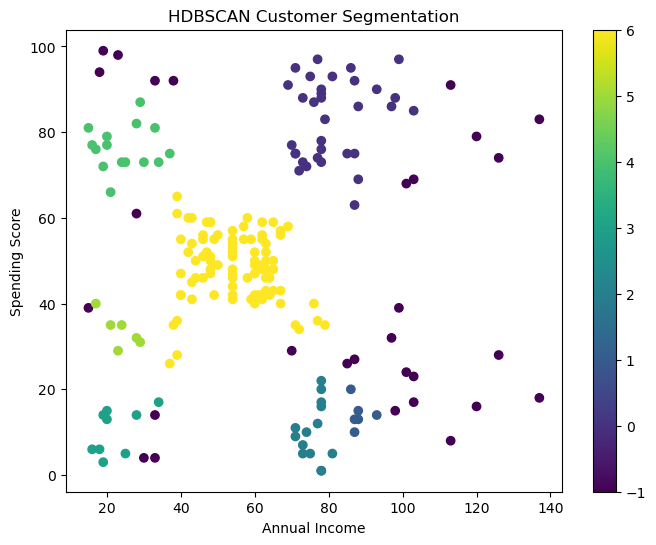

In [27]:
plt.figure(figsize=(8,6))

plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['Cluster'],
    cmap='viridis'
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("HDBSCAN Customer Segmentation")

plt.colorbar()
plt.show()

# 12: PCA

In [28]:
import pandas as pd

In [29]:
df = pd.read_csv('Downloads/mobile_price (1).csv')

In [30]:
df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [31]:
x = df.drop(columns = 'price_range')
y = df['price_range']

In [32]:
from sklearn.preprocessing import StandardScaler

In [33]:
scaler = StandardScaler()

In [34]:
pd.DataFrame(scaler.fit_transform(x), columns =x.columns)

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,-0.902597,-0.990050,0.830779,-1.019184,-0.762495,-1.043966,-1.380644,0.340740,1.349249,-1.101971,-1.305750,-1.408949,-1.146784,0.391703,-0.784983,0.283103,1.462493,-1.786861,-1.006018,0.986097
1,-0.495139,1.010051,-1.253064,0.981177,-0.992890,0.957886,1.155024,0.687548,-0.120059,-0.664768,-0.645989,0.585778,1.704465,0.467317,1.114266,-0.635317,-0.734267,0.559641,0.994018,-1.014099
2,-1.537686,1.010051,-1.253064,0.981177,-0.532099,0.957886,0.493546,1.381165,0.134244,0.209639,-0.645989,1.392684,1.074968,0.441498,-0.310171,-0.864922,-0.368140,0.559641,0.994018,-1.014099
3,-1.419319,1.010051,1.198517,-1.019184,-0.992890,-1.043966,-1.215274,1.034357,-0.261339,0.646842,-0.151168,1.286750,1.236971,0.594569,0.876859,0.512708,-0.002014,0.559641,-1.006018,-1.014099
4,1.325906,1.010051,-0.395011,-1.019184,2.002254,0.957886,0.658915,0.340740,0.021220,-1.101971,0.673534,1.268718,-0.091452,-0.657666,-1.022389,-0.864922,0.730240,0.559641,0.994018,-1.014099
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,-1.011860,1.010051,-1.253064,0.981177,-0.992890,0.957886,-1.656260,1.034357,-0.967737,0.646842,0.673534,1.300273,1.477661,-1.342799,0.164641,-0.405712,1.462493,0.559641,0.994018,-1.014099
1996,1.653694,1.010051,1.321096,0.981177,-0.992890,-1.043966,0.383299,-1.046495,1.320993,-0.227564,-1.140810,0.608317,1.651235,-0.085031,-0.310171,0.971917,0.913303,0.559641,0.994018,0.986097
1997,1.530773,-0.990050,-0.762748,0.981177,-0.762495,0.957886,0.217930,0.687548,-0.911225,1.521249,-1.140810,0.502383,0.880565,0.860139,-0.784983,-1.094526,-1.100394,0.559641,0.994018,-1.014099
1998,0.622527,-0.990050,-0.762748,-1.019184,-0.071307,0.957886,0.769162,-1.393304,0.134244,0.209639,-0.810929,-0.696707,-1.345816,-1.157454,1.351672,0.971917,1.462493,0.559641,0.994018,0.986097


In [35]:
x.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,842,0,2.2,0,1,0,7,0.6,188,2,2,20,756,2549,9,7,19,0,0,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,6,905,1988,2631,17,3,7,1,1,0
2,563,1,0.5,1,2,1,41,0.9,145,5,6,1263,1716,2603,11,2,9,1,1,0
3,615,1,2.5,0,0,0,10,0.8,131,6,9,1216,1786,2769,16,8,11,1,0,0
4,1821,1,1.2,0,13,1,44,0.6,141,2,14,1208,1212,1411,8,2,15,1,1,0


In [36]:
from sklearn.decomposition import PCA

In [37]:
pca = PCA(n_components = 4)

In [38]:
x_pca = pd.DataFrame(pca.fit_transform(x))

In [39]:
x_pca.head()

,0,1,2,3
0,430.597094,-795.788231,-390.070331,55.636140
1,504.984735,696.622368,-235.629081,343.925977
2,473.329828,763.942136,-680.059466,-113.916880
3,639.822324,779.691180,-630.783647,-30.402246
4,-718.985184,382.304525,591.040362,-392.357235


# 13: K-FOLD

In [40]:
import pandas as pd

In [41]:
df = pd.read_csv('Downloads/diabetes.csv')

In [42]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [43]:
x = df.drop(columns = ['Outcome'])
y = df['Outcome']

In [44]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

In [45]:
def get_score(model, x_test,y_test):
  model.fit(x_train,y_train)
  return model.score(x_test, y_test)

In [46]:
folds = StratifiedKFold(n_splits = 3)

In [47]:
for train, test in folds.split(x,y):
  x_train,x_test,y_train,y_test = train_test_split(x, y ,test_size = 0.2)
  print(get_score(RandomForestClassifier(), x_test,y_test))

0.7402597402597403
0.7402597402597403
0.7272727272727273


In [48]:
from sklearn.model_selection import cross_val_score

In [49]:
cross_val_score(DecisionTreeClassifier(), x, y, cv = 3)

array([0.66015625, 0.6953125 , 0.7109375 ])

# 14: HYPER PARAMETER TUNING

In [50]:
import pandas as pd

In [51]:
df = pd.read_csv('Downloads/diabetes.csv')

In [52]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [53]:
x = df.drop(columns = ['Outcome'])
y = df['Outcome']

In [54]:
from sklearn.model_selection import train_test_split

In [55]:
x_train, x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2)

In [56]:
from sklearn.ensemble import RandomForestClassifier

In [57]:
from sklearn.model_selection import GridSearchCV

In [58]:
params = {'n_estimators': list(range(1,50)), 'criterion': ['gini','entropy'], 'max_depth':[None,1,2,3]}

In [59]:
gsv = GridSearchCV(RandomForestClassifier(), params,cv = 5, scoring = 'accuracy')

In [60]:
gsv.fit(x_train,y_train)

,estimator,RandomForestClassifier()
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_depth': [None, 1, ...], 'n_estimators': [1, 2, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,26


In [62]:
gsv.score(x_train,y_train)

0.8013029315960912

In [63]:
gsv.best_params_

{'criterion': 'entropy', 'max_depth': 3, 'n_estimators': 26}

In [64]:
gsv.best_score_

np.float64(0.7719978675196588)

## B: ASSOCIATION

# APRIORI ALGORITHM

In [1]:
pip install mlxtend

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
# Apriori requires data in binary format (True/False).
# TransactionEncoder converts transaction lists into one-hot encoded format.

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

# apriori() finds frequent itemsets.
# association_rules() generates rules from frequent itemsets.

In [8]:
df = pd.read_csv('Downloads/market_basket_transactions_extended.csv')

In [9]:
df

,TransactionID,Items
0,1,"Milk,Bread,Butter"
1,2,"Milk,Bread"
2,3,"Milk,Butter"
3,4,"Bread,Butter"
4,5,"Milk,Bread,Butter,Eggs"
5,6,"Milk,Eggs"
6,7,"Bread,Eggs"
7,8,"Butter,Eggs"
8,9,"Milk,Bread,Cheese"
9,10,"Milk,Cheese,Butter"


In [10]:
transactions = []

for item in df['Items']:
    transactions.append(item.split(','))

In [11]:
# Creates encoder object.Think of it as a converter that transforms transactions into machine-readable format.
te = TransactionEncoder()

te_array = te.fit(transactions).transform(transactions)  # Converts transaction data into True/False values.

basket = pd.DataFrame(te_array,
                      columns=te.columns_)

In [12]:
print(basket.head())

   Bread  Butter  Cheese   Eggs    Jam   Milk
0   True    True   False  False  False   True
1   True   False   False  False  False   True
2  False    True   False  False  False   True
3   True    True   False  False  False  False
4   True    True   False   True  False   True


In [13]:
frequent_itemsets = apriori(
    basket,
    min_support=0.2,
    use_colnames=True  # Instead of: 1 2 3 display actual names: milk,bread,butter
)

print(frequent_itemsets)

    support               itemsets
0      0.65                (Bread)
1      0.60               (Butter)
2      0.40               (Cheese)
3      0.45                 (Eggs)
4      0.25                  (Jam)
5      0.65                 (Milk)
6      0.40        (Butter, Bread)
7      0.25        (Bread, Cheese)
8      0.25          (Eggs, Bread)
9      0.20           (Jam, Bread)
10     0.40          (Bread, Milk)
11     0.20       (Butter, Cheese)
12     0.20         (Butter, Eggs)
13     0.20          (Butter, Jam)
14     0.35         (Butter, Milk)
15     0.20         (Eggs, Cheese)
16     0.30         (Milk, Cheese)
17     0.25           (Eggs, Milk)
18     0.20  (Butter, Bread, Milk)
19     0.20  (Bread, Cheese, Milk)


In [14]:
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.6
)

print(rules[['antecedents',
             'consequents',
             'support',
             'confidence',
             'lift']])

       antecedents consequents  support  confidence      lift
0         (Butter)     (Bread)     0.40    0.666667  1.025641
1          (Bread)    (Butter)     0.40    0.615385  1.025641
2         (Cheese)     (Bread)     0.25    0.625000  0.961538
3            (Jam)     (Bread)     0.20    0.800000  1.230769
4          (Bread)      (Milk)     0.40    0.615385  0.946746
5           (Milk)     (Bread)     0.40    0.615385  0.946746
6            (Jam)    (Butter)     0.20    0.800000  1.333333
7         (Cheese)      (Milk)     0.30    0.750000  1.153846
8  (Bread, Cheese)      (Milk)     0.20    0.800000  1.230769
9   (Milk, Cheese)     (Bread)     0.20    0.666667  1.025641


In [15]:
rules = rules.sort_values(
    by='lift',
    ascending=False
)

print(rules.head())

       antecedents consequents  antecedent support  consequent support  \
6            (Jam)    (Butter)                0.25                0.60   
3            (Jam)     (Bread)                0.25                0.65   
8  (Bread, Cheese)      (Milk)                0.25                0.65   
7         (Cheese)      (Milk)                0.40                0.65   
0         (Butter)     (Bread)                0.60                0.65   

   support  confidence      lift  representativity  leverage  conviction  \
6      0.2    0.800000  1.333333               1.0    0.0500        2.00   
3      0.2    0.800000  1.230769               1.0    0.0375        1.75   
8      0.2    0.800000  1.230769               1.0    0.0375        1.75   
7      0.3    0.750000  1.153846               1.0    0.0400        1.40   
0      0.4    0.666667  1.025641               1.0    0.0100        1.05   

   zhangs_metric   jaccard  certainty  kulczynski  
6       0.333333  0.307692   0.500000    0.566

# FP-Growth (Frequent Pattern Growth) algorithm

In [34]:
import pandas as pd

In [35]:
dataset = [
    ['Bread','Milk'],
    ['Bread','Diaper','Beer','Eggs'],
    ['Milk','Diaper','Beer','Coke'],
    ['Bread','Milk','Diaper','Beer'],
    ['Bread','Milk','Diaper','Coke']
]

df = pd.DataFrame(dataset)
print(df)

       0       1       2     3
0  Bread    Milk    None  None
1  Bread  Diaper    Beer  Eggs
2   Milk  Diaper    Beer  Coke
3  Bread    Milk  Diaper  Beer
4  Bread    Milk  Diaper  Coke


In [36]:
from mlxtend.preprocessing import TransactionEncoder

te = TransactionEncoder()

te_array = te.fit(dataset).transform(dataset)

df_encoded = pd.DataFrame(
    te_array,
    columns=te.columns_
)

print(df_encoded)

    Beer  Bread   Coke  Diaper   Eggs   Milk
0  False   True  False   False  False   True
1   True   True  False    True   True  False
2   True  False   True    True  False   True
3   True   True  False    True  False   True
4  False   True   True    True  False   True


In [37]:
from mlxtend.frequent_patterns import fpgrowth

frequent_itemsets = fpgrowth(
    df_encoded,
    min_support=0.4,
    use_colnames=True
)

print(frequent_itemsets)

    support               itemsets
0       0.8                 (Milk)
1       0.8                (Bread)
2       0.8               (Diaper)
3       0.6                 (Beer)
4       0.4                 (Coke)
5       0.6          (Bread, Milk)
6       0.6        (Diaper, Bread)
7       0.4  (Diaper, Bread, Milk)
8       0.6         (Diaper, Milk)
9       0.6         (Diaper, Beer)
10      0.4          (Bread, Beer)
11      0.4           (Milk, Beer)
12      0.4  (Diaper, Bread, Beer)
13      0.4   (Diaper, Milk, Beer)
14      0.4         (Coke, Diaper)
15      0.4           (Coke, Milk)
16      0.4   (Coke, Diaper, Milk)


In [38]:
from mlxtend.frequent_patterns import association_rules

rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.6
)

print(rules)

        antecedents      consequents  antecedent support  consequent support  \
0           (Bread)           (Milk)                 0.8                 0.8   
1            (Milk)          (Bread)                 0.8                 0.8   
2          (Diaper)          (Bread)                 0.8                 0.8   
3           (Bread)         (Diaper)                 0.8                 0.8   
4   (Diaper, Bread)           (Milk)                 0.6                 0.8   
5    (Diaper, Milk)          (Bread)                 0.6                 0.8   
6     (Bread, Milk)         (Diaper)                 0.6                 0.8   
7          (Diaper)           (Milk)                 0.8                 0.8   
8            (Milk)         (Diaper)                 0.8                 0.8   
9          (Diaper)           (Beer)                 0.8                 0.6   
10           (Beer)         (Diaper)                 0.6                 0.8   
11           (Beer)          (Bread)    

In [39]:
max_support = frequent_itemsets['support'].max()

most_frequent = frequent_itemsets[
    frequent_itemsets['support'] == max_support
]

print(most_frequent)

   support  itemsets
0      0.8    (Milk)
1      0.8   (Bread)
2      0.8  (Diaper)
